# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-12-05"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p14"
subproj <- "AVGUSTINOVA_24_25"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "MALAT1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

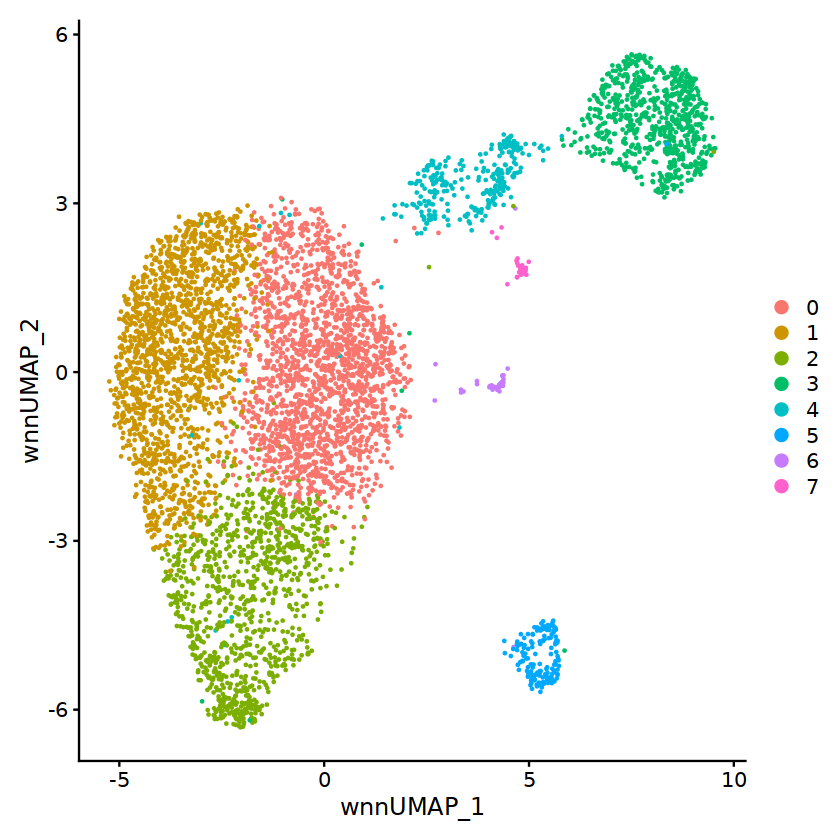

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

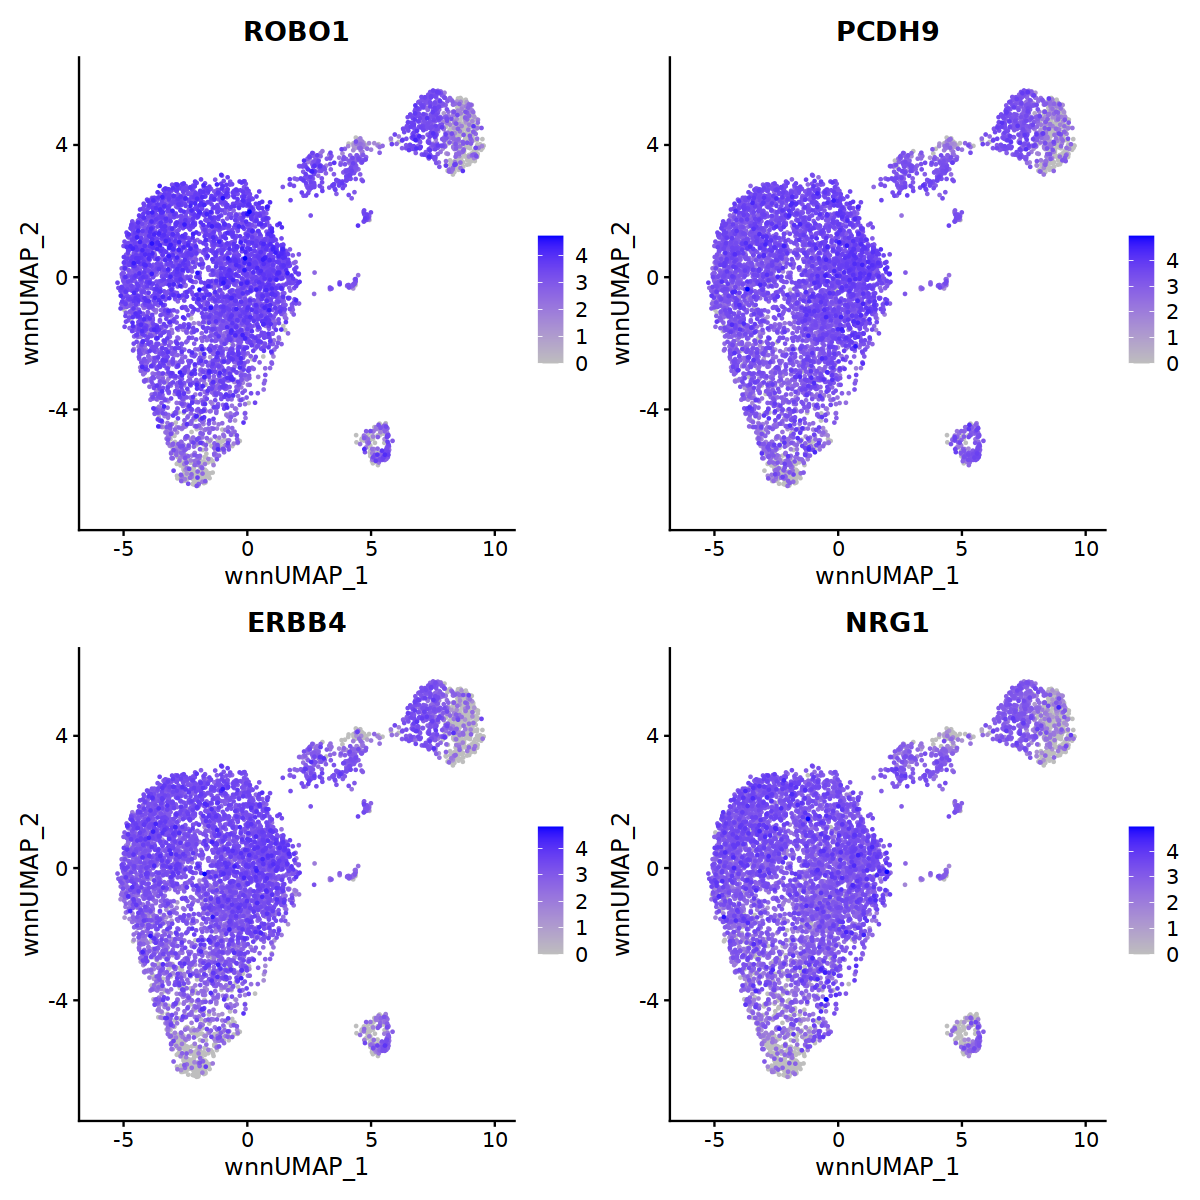

In [11]:
options(repr.plot.width = 10, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("ROBO1","PCDH9", "ERBB4","NRG1"),ncol=2,
            cols = c("gray", "blue"),  order=T)

## Re-normalize

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

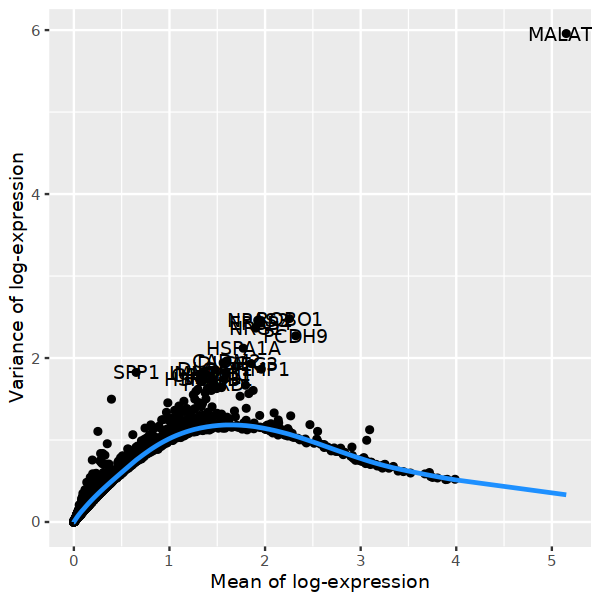

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 4627
[1] 4626


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  ROBO1, PCDH9, ERBB4, NRG1, NPAS3, CADM2, GMDS, SEMA3D, SYNE2, CDH4 
	   BICD1, DLGAP1, AFF3, MEG3, NRXN1, MIR99AHG, BRINP3, DLG2, PCDH7, PTPRD 
	   SEMA3E, FGFR1, SNTG1, CTNNA3, NTN1, INPP4B, GRID2, EPHA5, DLC1, IMMP2L 
Negative:  PLXDC2, SPP1, C1QC, C1QB, CD74, IFI30, TGFBI, LRMDA, C1QA, CD163 
	   RNASE1, SLC11A1, SLCO2B1, DOCK4, ZEB2, CD14, FMN1, TYROBP, LDLRAD4, STAB1 
	   SFMBT2, DOCK8, PTPRJ, LAPTM5, ALOX5AP, LRP1, FCER1G, TNS3, TBXAS1, VSIG4 
PC_ 2 
Positive:  CADM1, NRG1, ERBB4, RBM47, CADM2, C1QC, INPP4B, FNDC3B, SNTG1, SEMA3D 
	   DLGAP1, GRID2, C1QA, IFI30, SLC1A3, C1QB, CDH4, LRMDA, NRXN1, IMMP2L 
	   CD163, GMDS, NPAS3, BRINP3, PCDH7, AL390957.1, ADAP2, CTNNA3, EPHA5, ROBO1 
Negative:  COL1A1, COL6A3, COL3A1, LAMA2, DCN, COL6A1, FN1, PDGFRB, TIMP3, RORA 
	   ZEB1, COL4A2, CDH11, PTPRG, PRICKLE1, MGP, COL4A1, COL5A2, NTM, IGFBP5 
	   IGFBP2, BGN, SVIL, LAMC3, BICC1, CACNA1C, AEBP1, COL8A1, SPARC, PCOLCE 
PC_ 3 
Positive: 

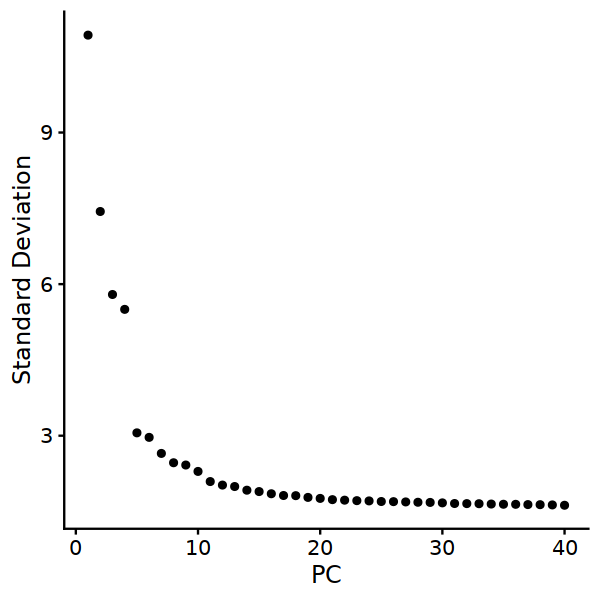

In [19]:
ElbowPlot(seurat_obj, n=40)

In [20]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


09:26:08 UMAP embedding parameters a = 0.9922 b = 1.112

09:26:08 Read 5747 rows and found 15 numeric columns

09:26:08 Using Annoy for neighbor search, n_neighbors = 30

09:26:08 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

09:26:09 Writing NN index file to temp file /scratch_tmp/51669760/RtmpFa9UAz/fileee575bb04314

09:26:09 Searching Annoy index using 1 thread, search_k = 3000

09:26:10 Annoy recall = 99.67%

09:26:11 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

09:26:11 68 smooth knn distance failures

09:26:13 Initializing from normalized Laplacian + noise (using irlba)

09:26:13 Commencing optimization for 500 epochs, with 241832 positive edges

09:26:30 Optimization 

In [21]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [22]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

09:26:46 UMAP embedding parameters a = 0.9922 b = 1.112

09:26:47 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

09:26:47 51 smooth knn distance failures

09:26:48 Initializing from normalized Laplacian + noise (using irlba)

09:26:48 Commencing optimization for 500 epochs, with 171412 positive edges

09:27:07 Optimization finished



In [23]:
seurat_obj <- FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5747
Number of edges: 226789

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9759
Number of communities: 10
Elapsed time: 0 seconds


1 singletons identified. 9 final clusters.



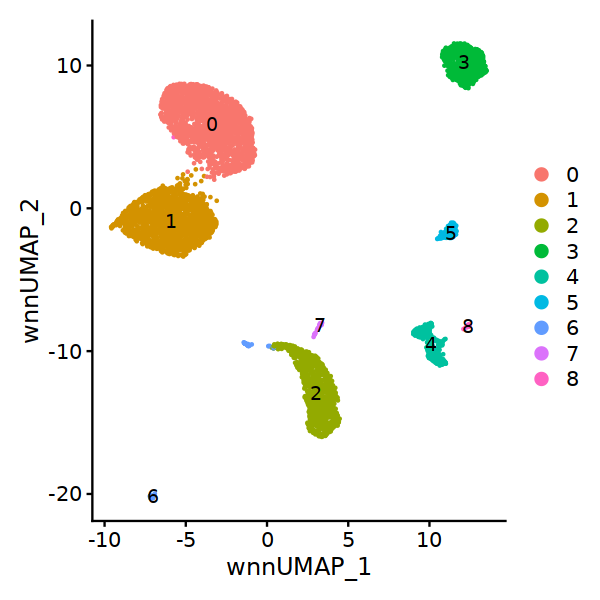

In [24]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

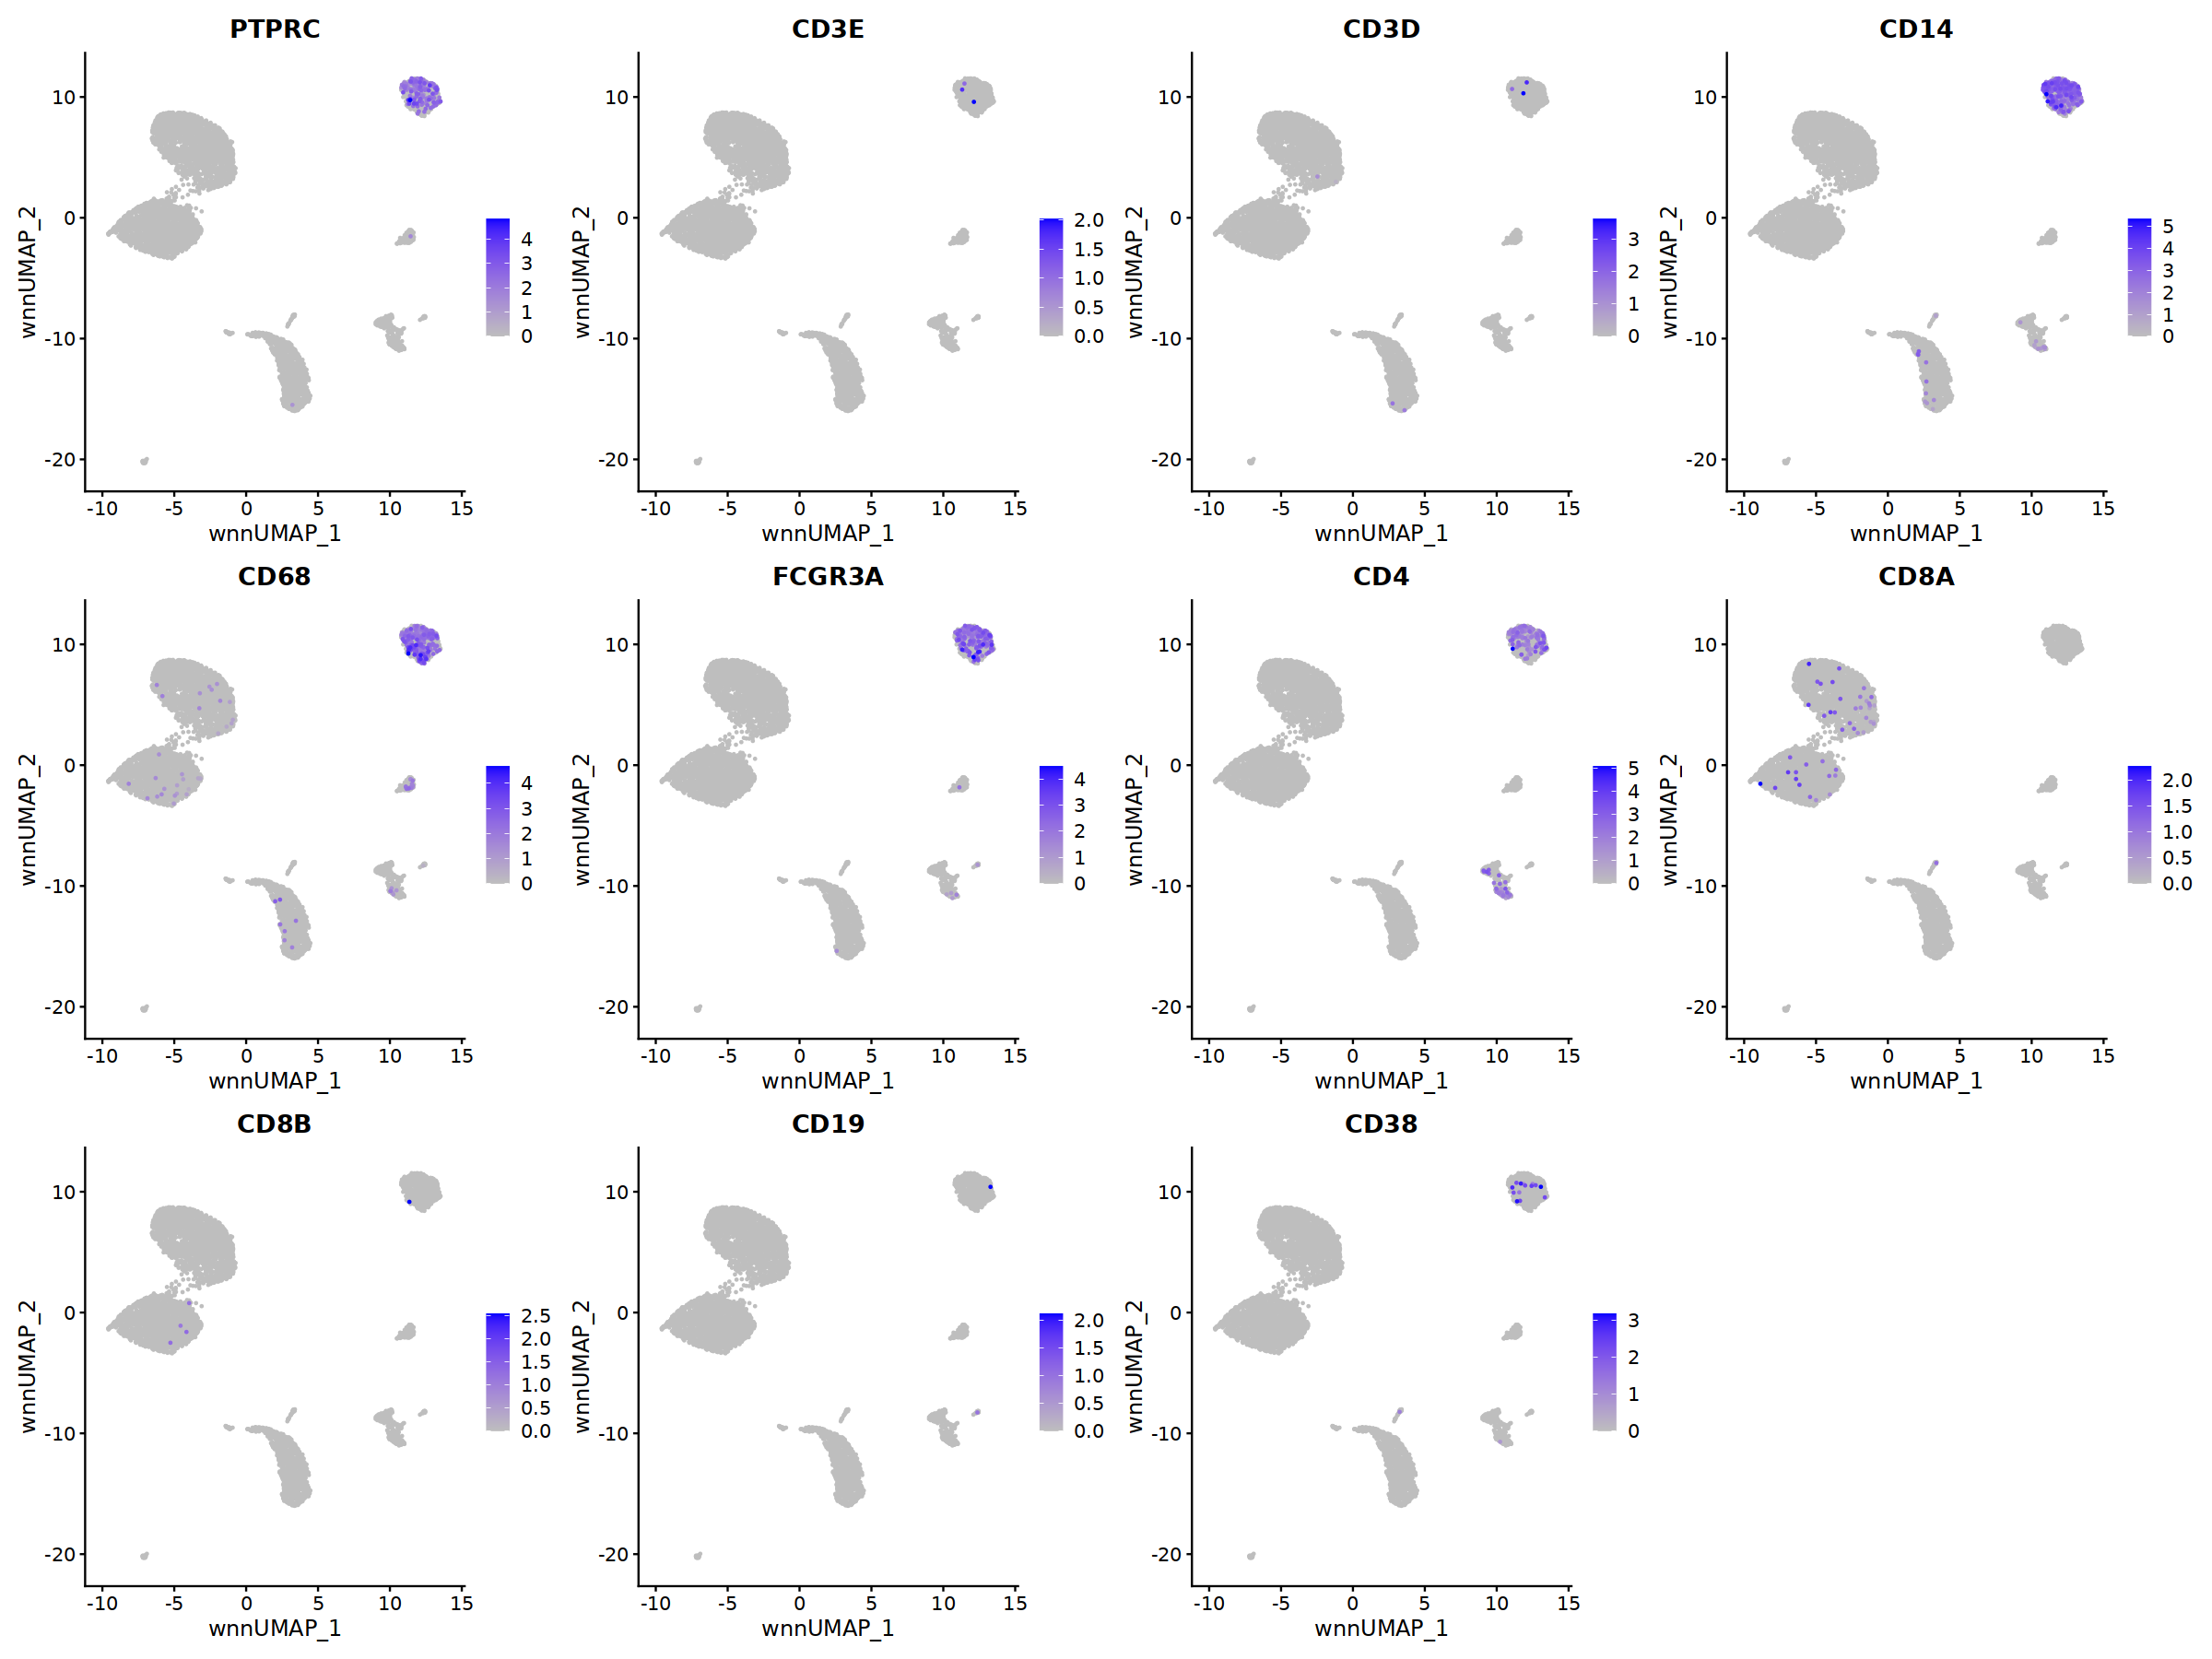

In [25]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

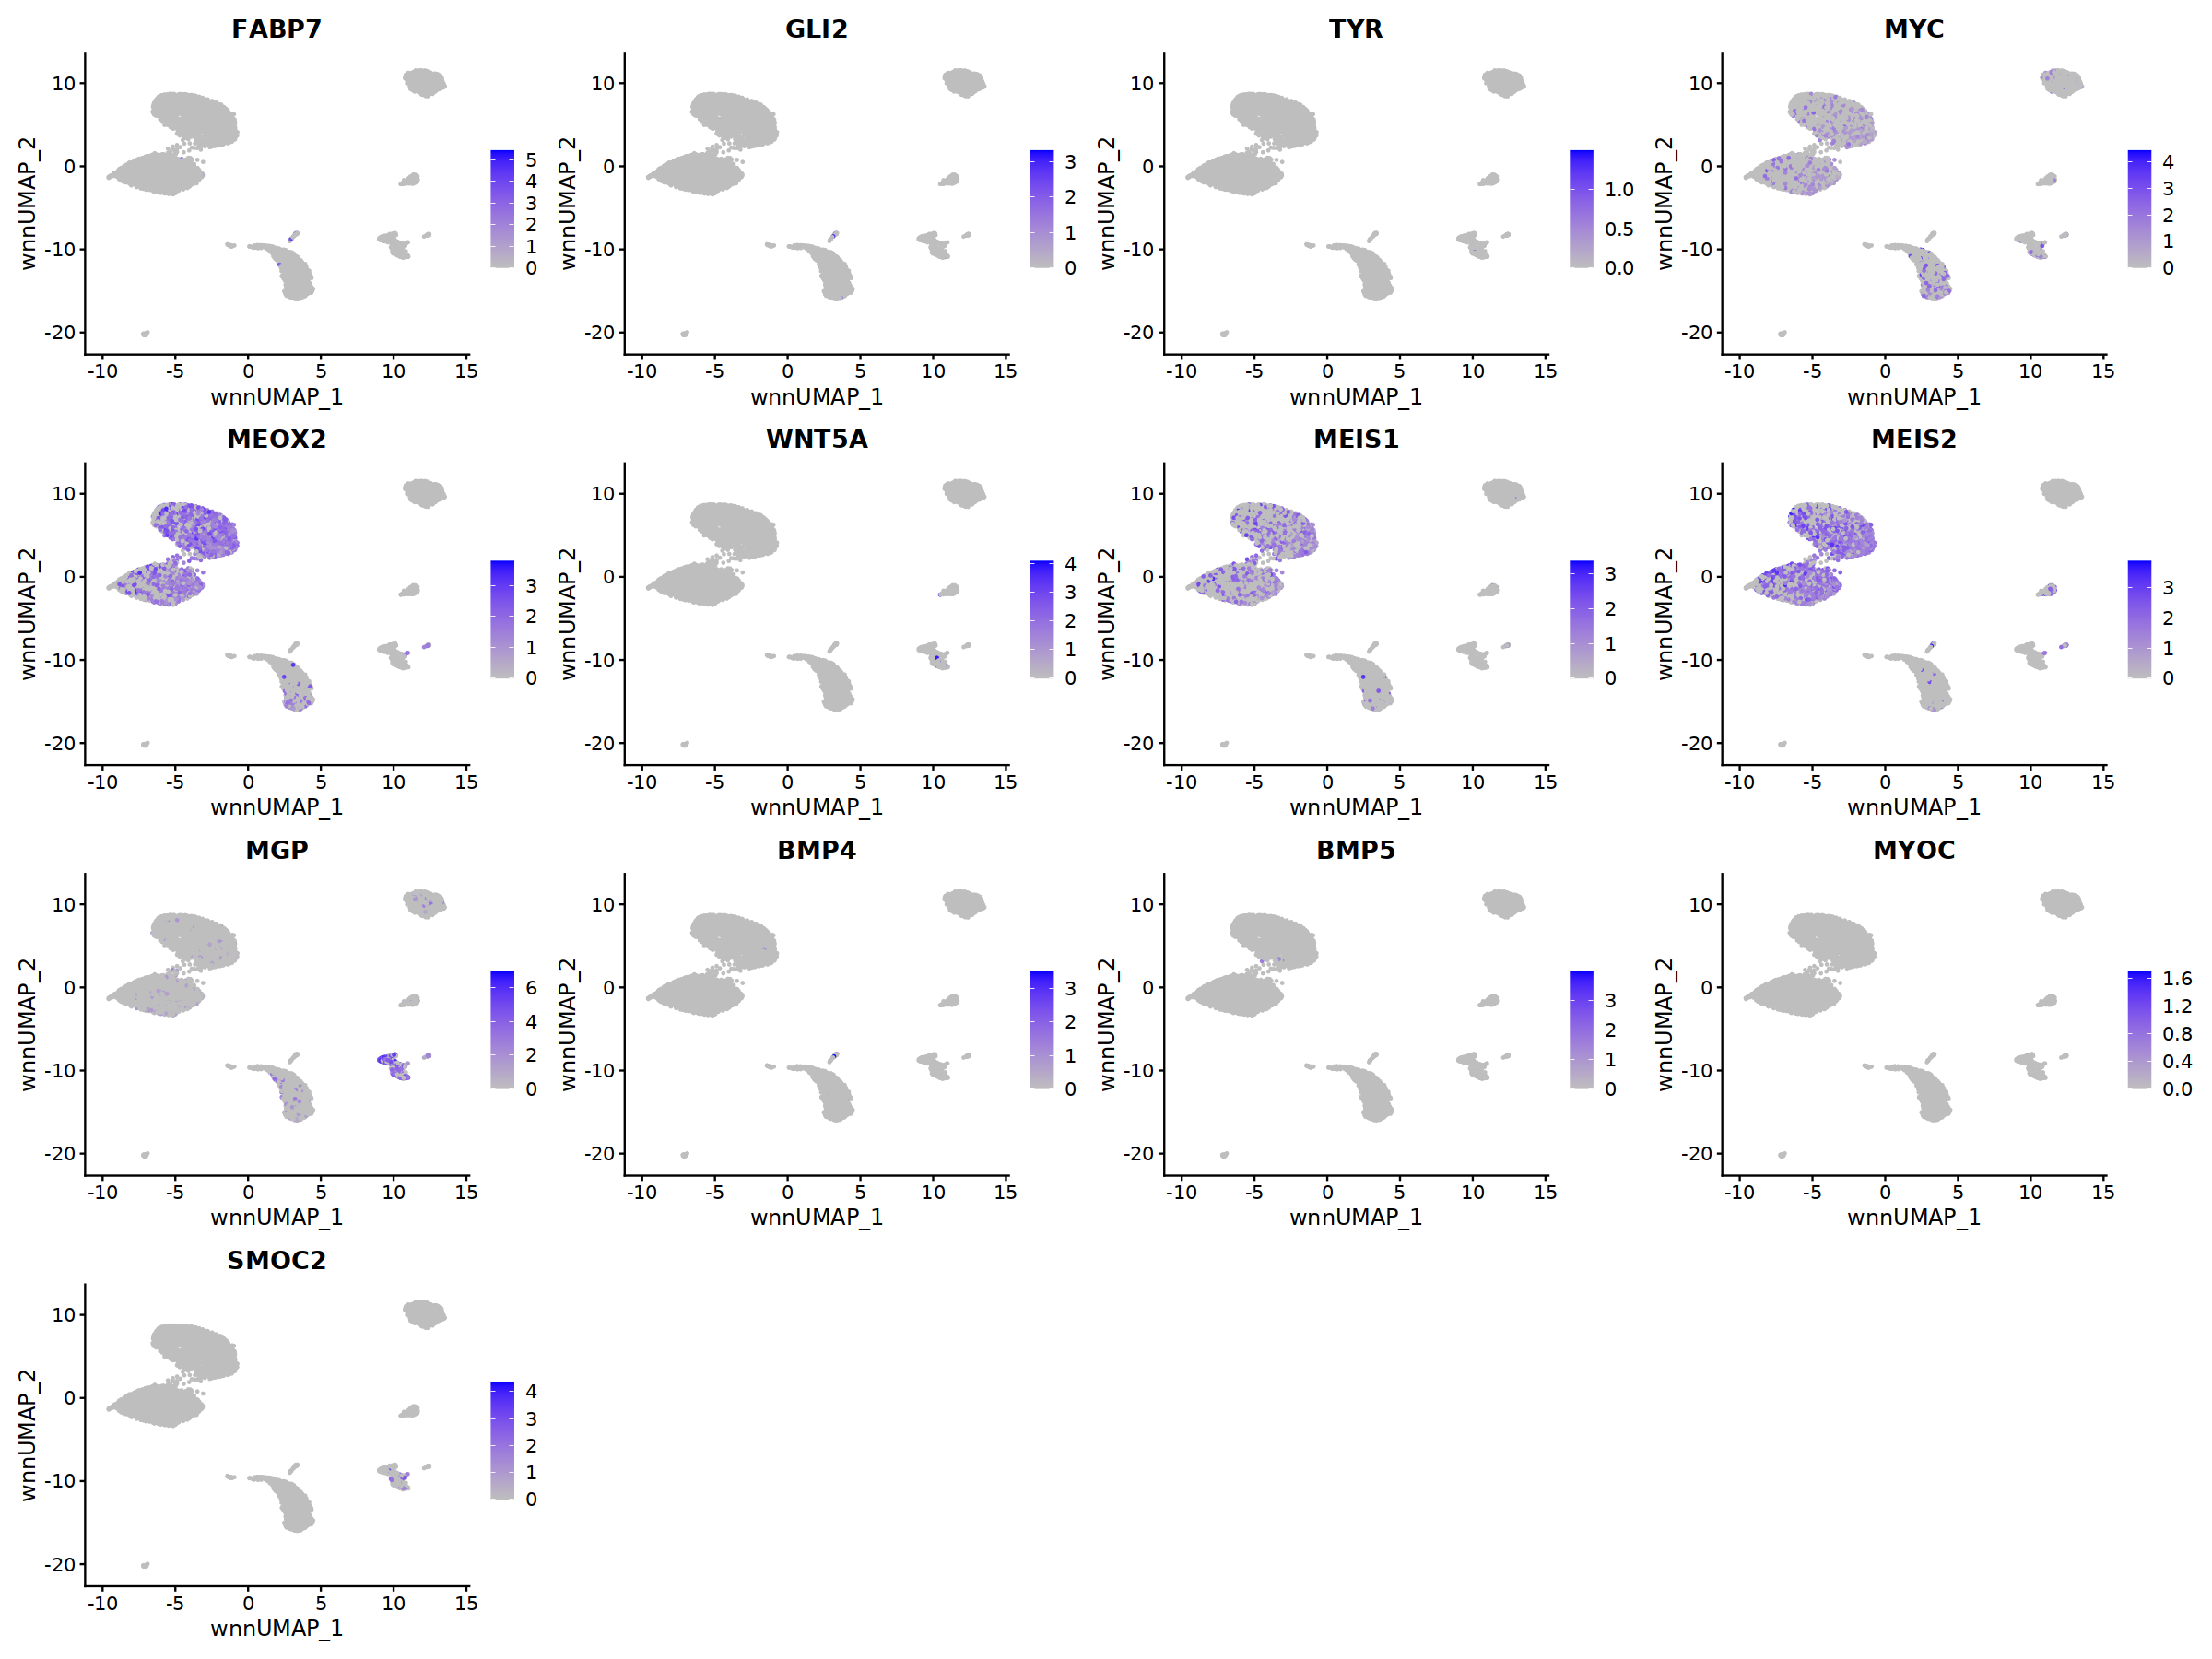

In [26]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

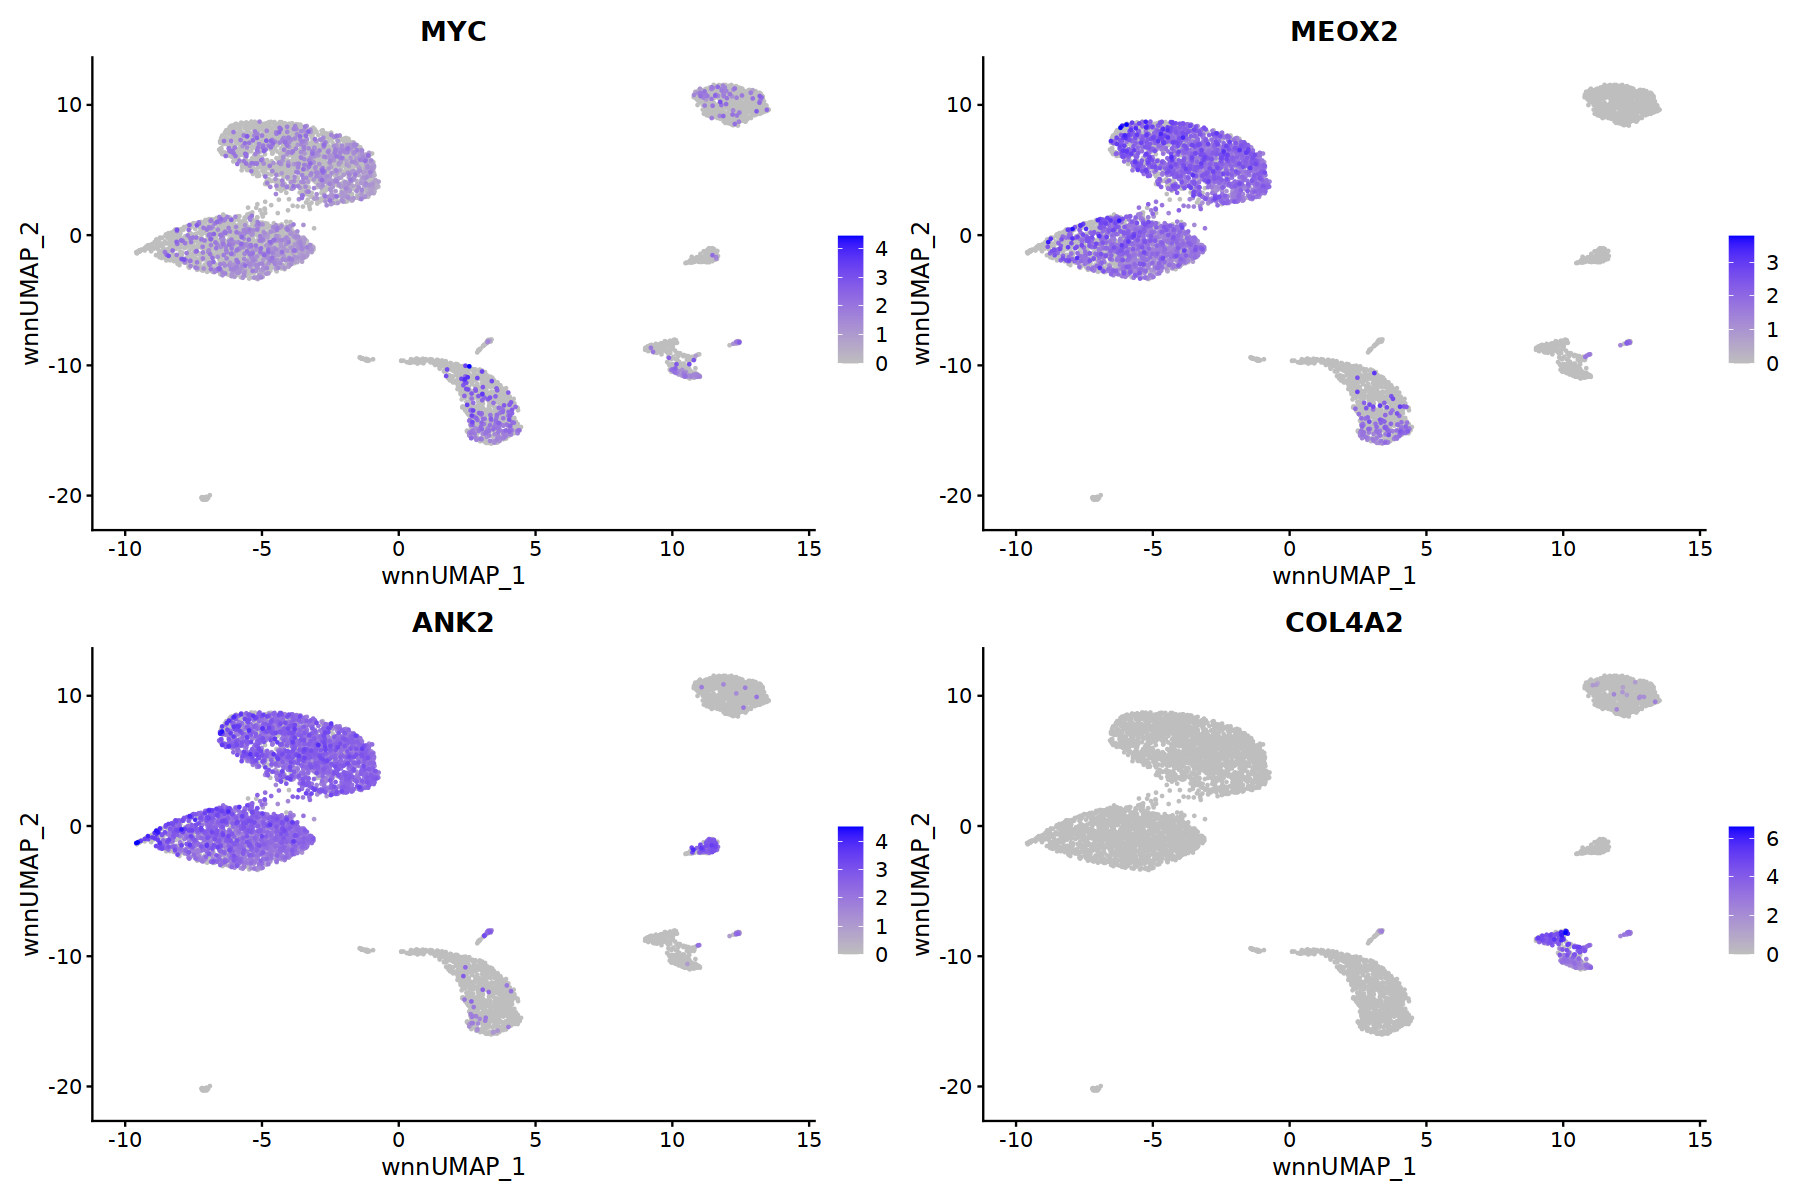

In [27]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MYC","MEOX2", "ANK2", "COL4A2"),ncol=2,
            cols = c("gray", "blue"),  order=T)

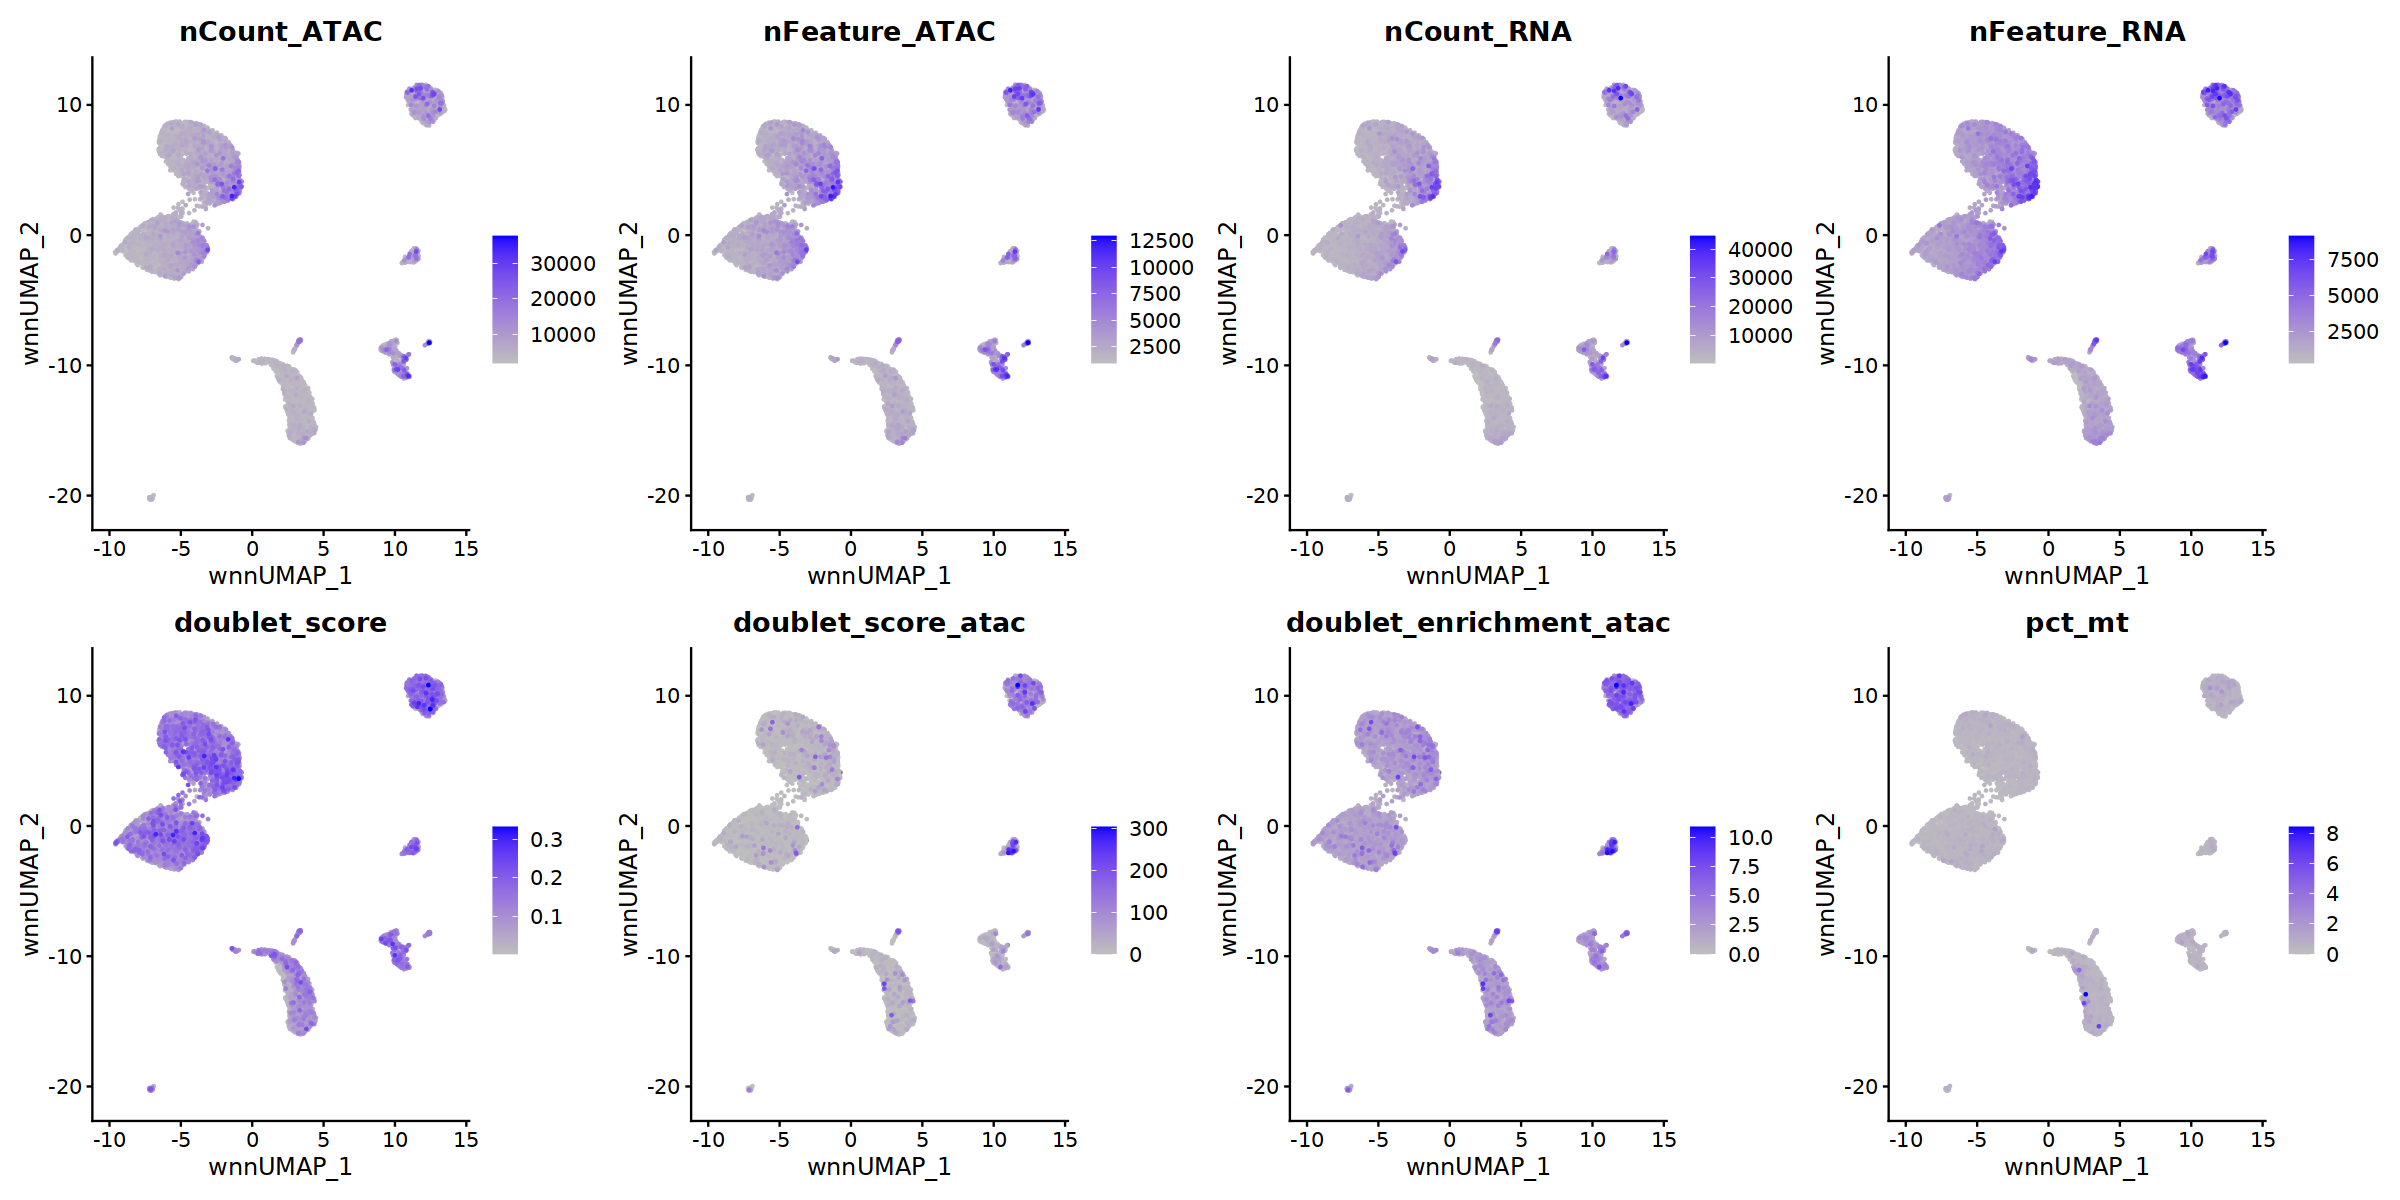

In [28]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

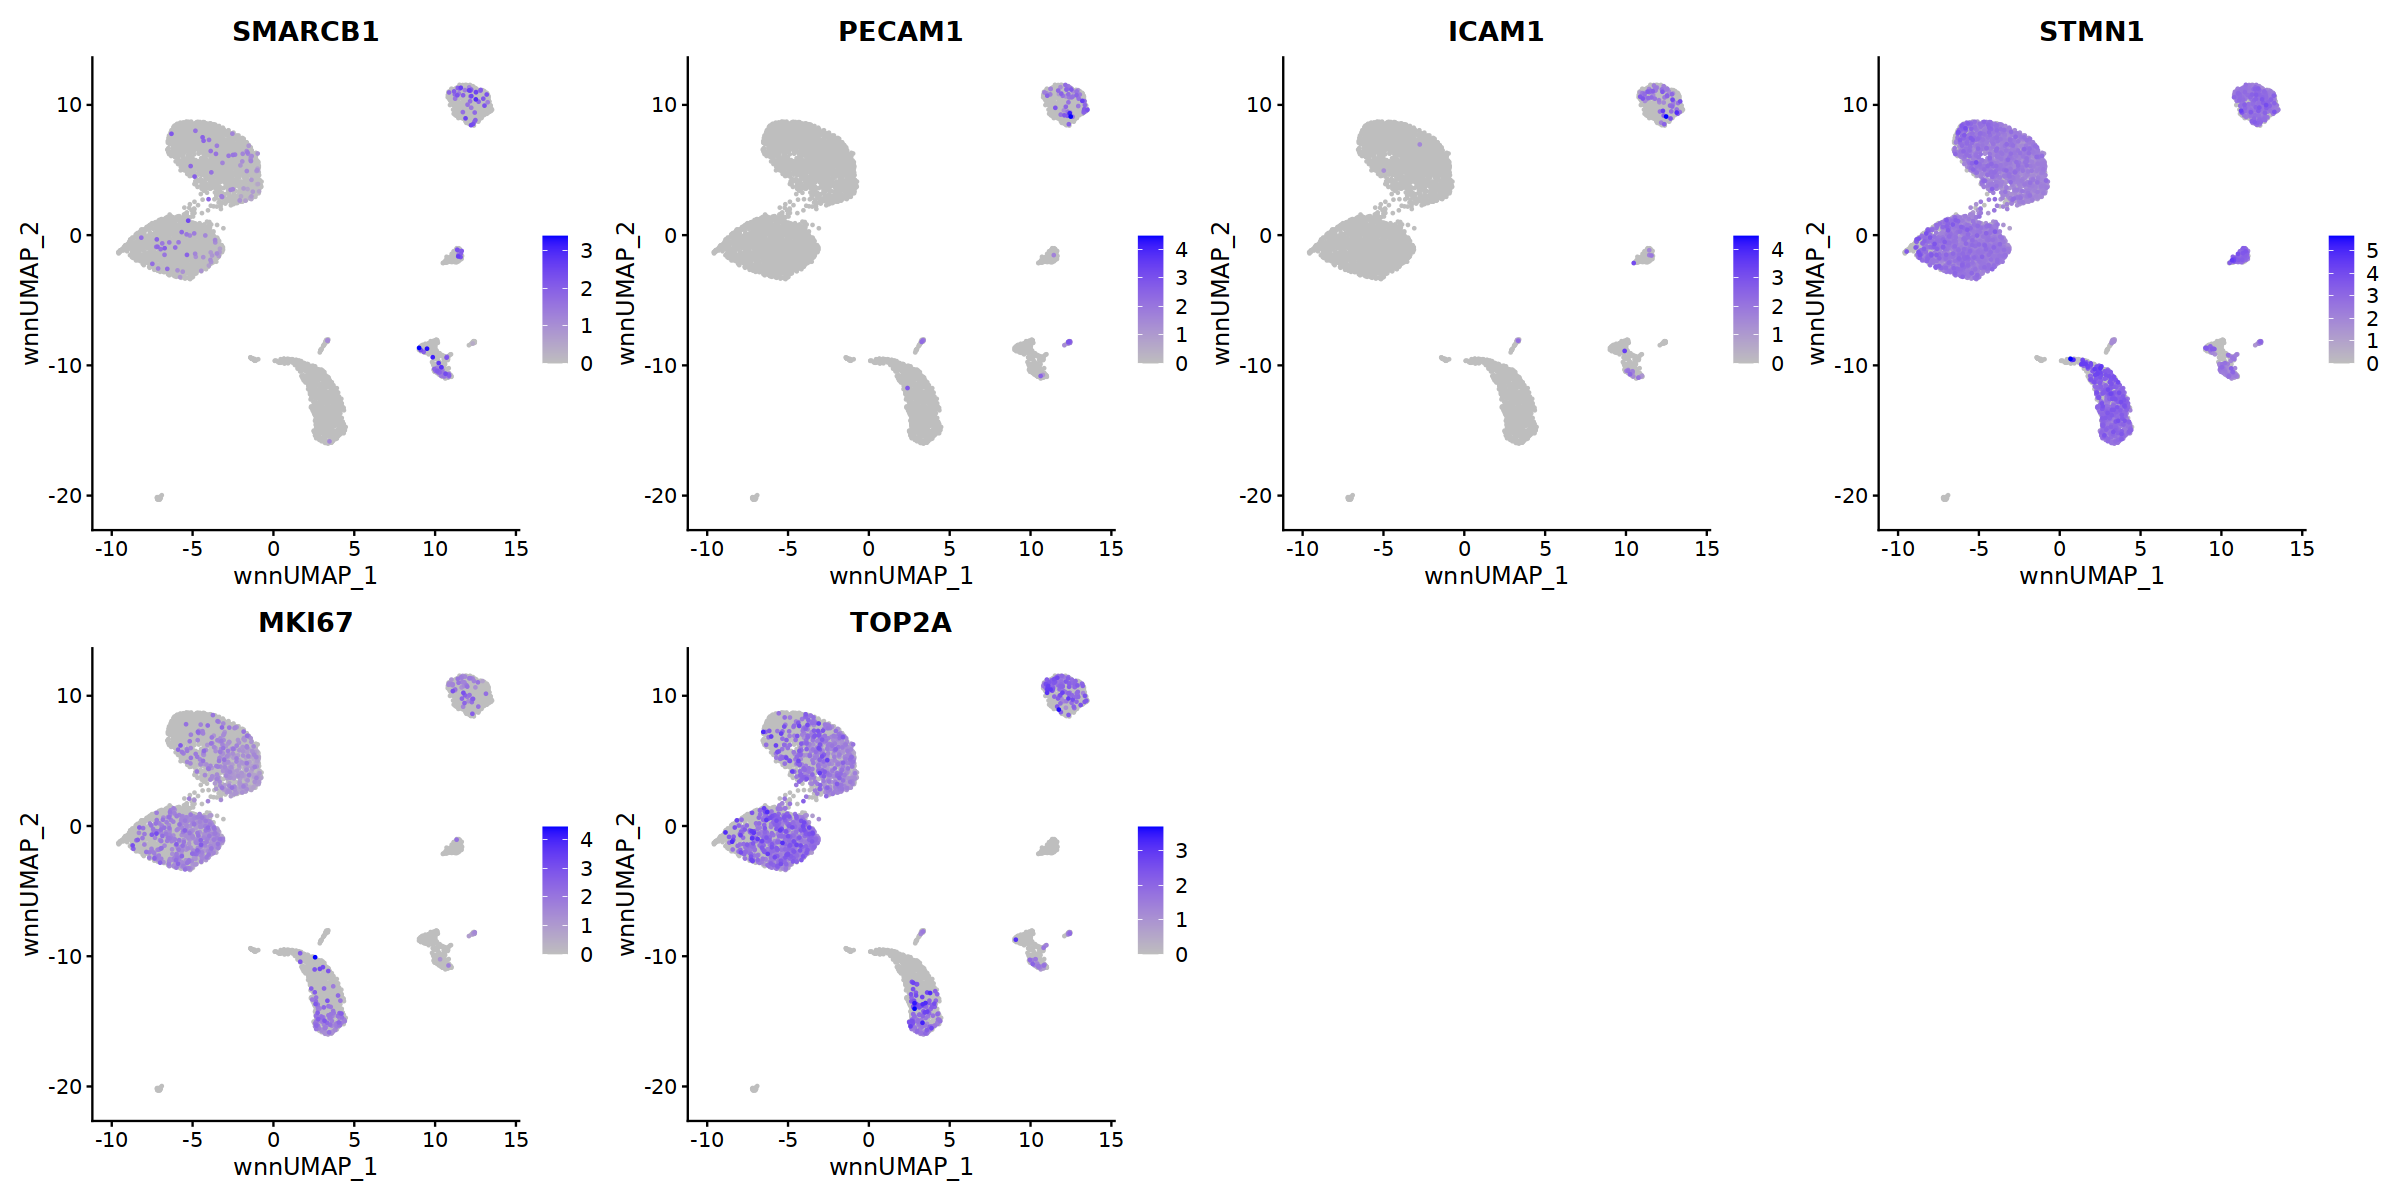

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [30]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8



In [31]:
rna.markers %>% 
  dplyr::filter(cluster == "7") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CHI3L1,0.000000e+00,7.141485,0.974,0.013,0.000000e+00,7,CHI3L1
GFAP,6.078716e-266,6.561928,0.795,0.015,1.705019e-261,7,GFAP
CRYAB1,4.223566e-55,6.507444,0.923,0.143,1.184668e-50,7,CRYAB
CLU1,6.184402e-50,5.731163,1.000,0.207,1.734663e-45,7,CLU
TNC,0.000000e+00,5.179135,0.769,0.005,0.000000e+00,7,TNC
SERPINA32,4.787988e-81,4.860862,0.769,0.058,1.342983e-76,7,SERPINA3
PTGDS2,9.708121e-69,4.484312,0.667,0.048,2.723031e-64,7,PTGDS
EFEMP1,0.000000e+00,4.306320,0.692,0.004,0.000000e+00,7,EFEMP1
MGST1,0.000000e+00,4.115054,0.718,0.008,0.000000e+00,7,MGST1


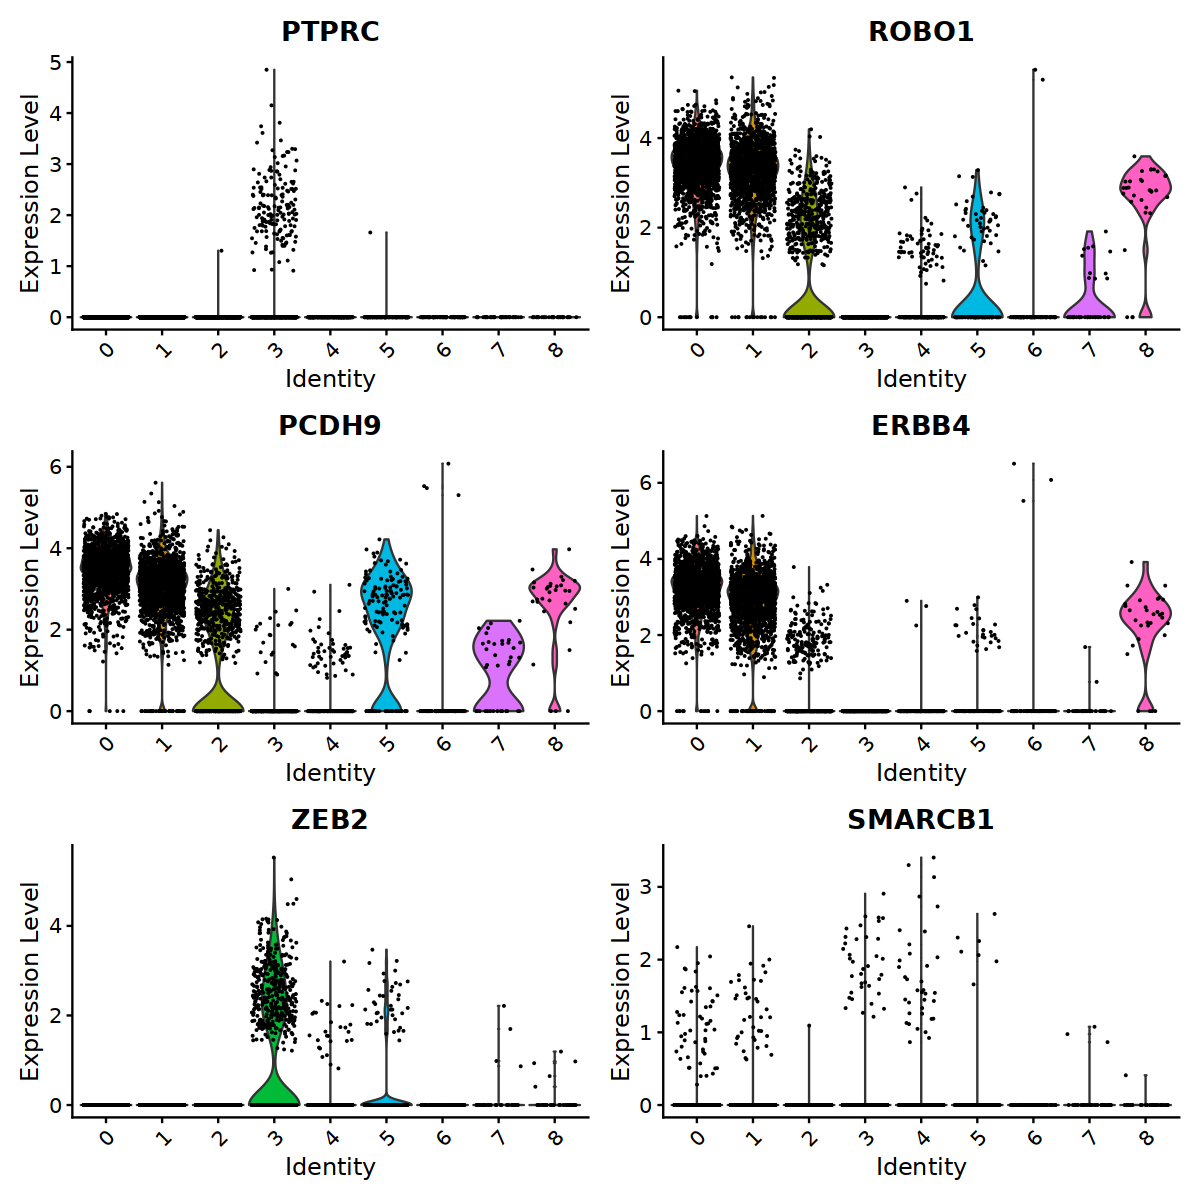

In [32]:
options(repr.plot.width = 10, repr.plot.height = 10)
VlnPlot(seurat_obj, 
            feature=c("PTPRC", "ROBO1","PCDH9", "ERBB4", "ZEB2", "SMARCB1"),ncol=2)

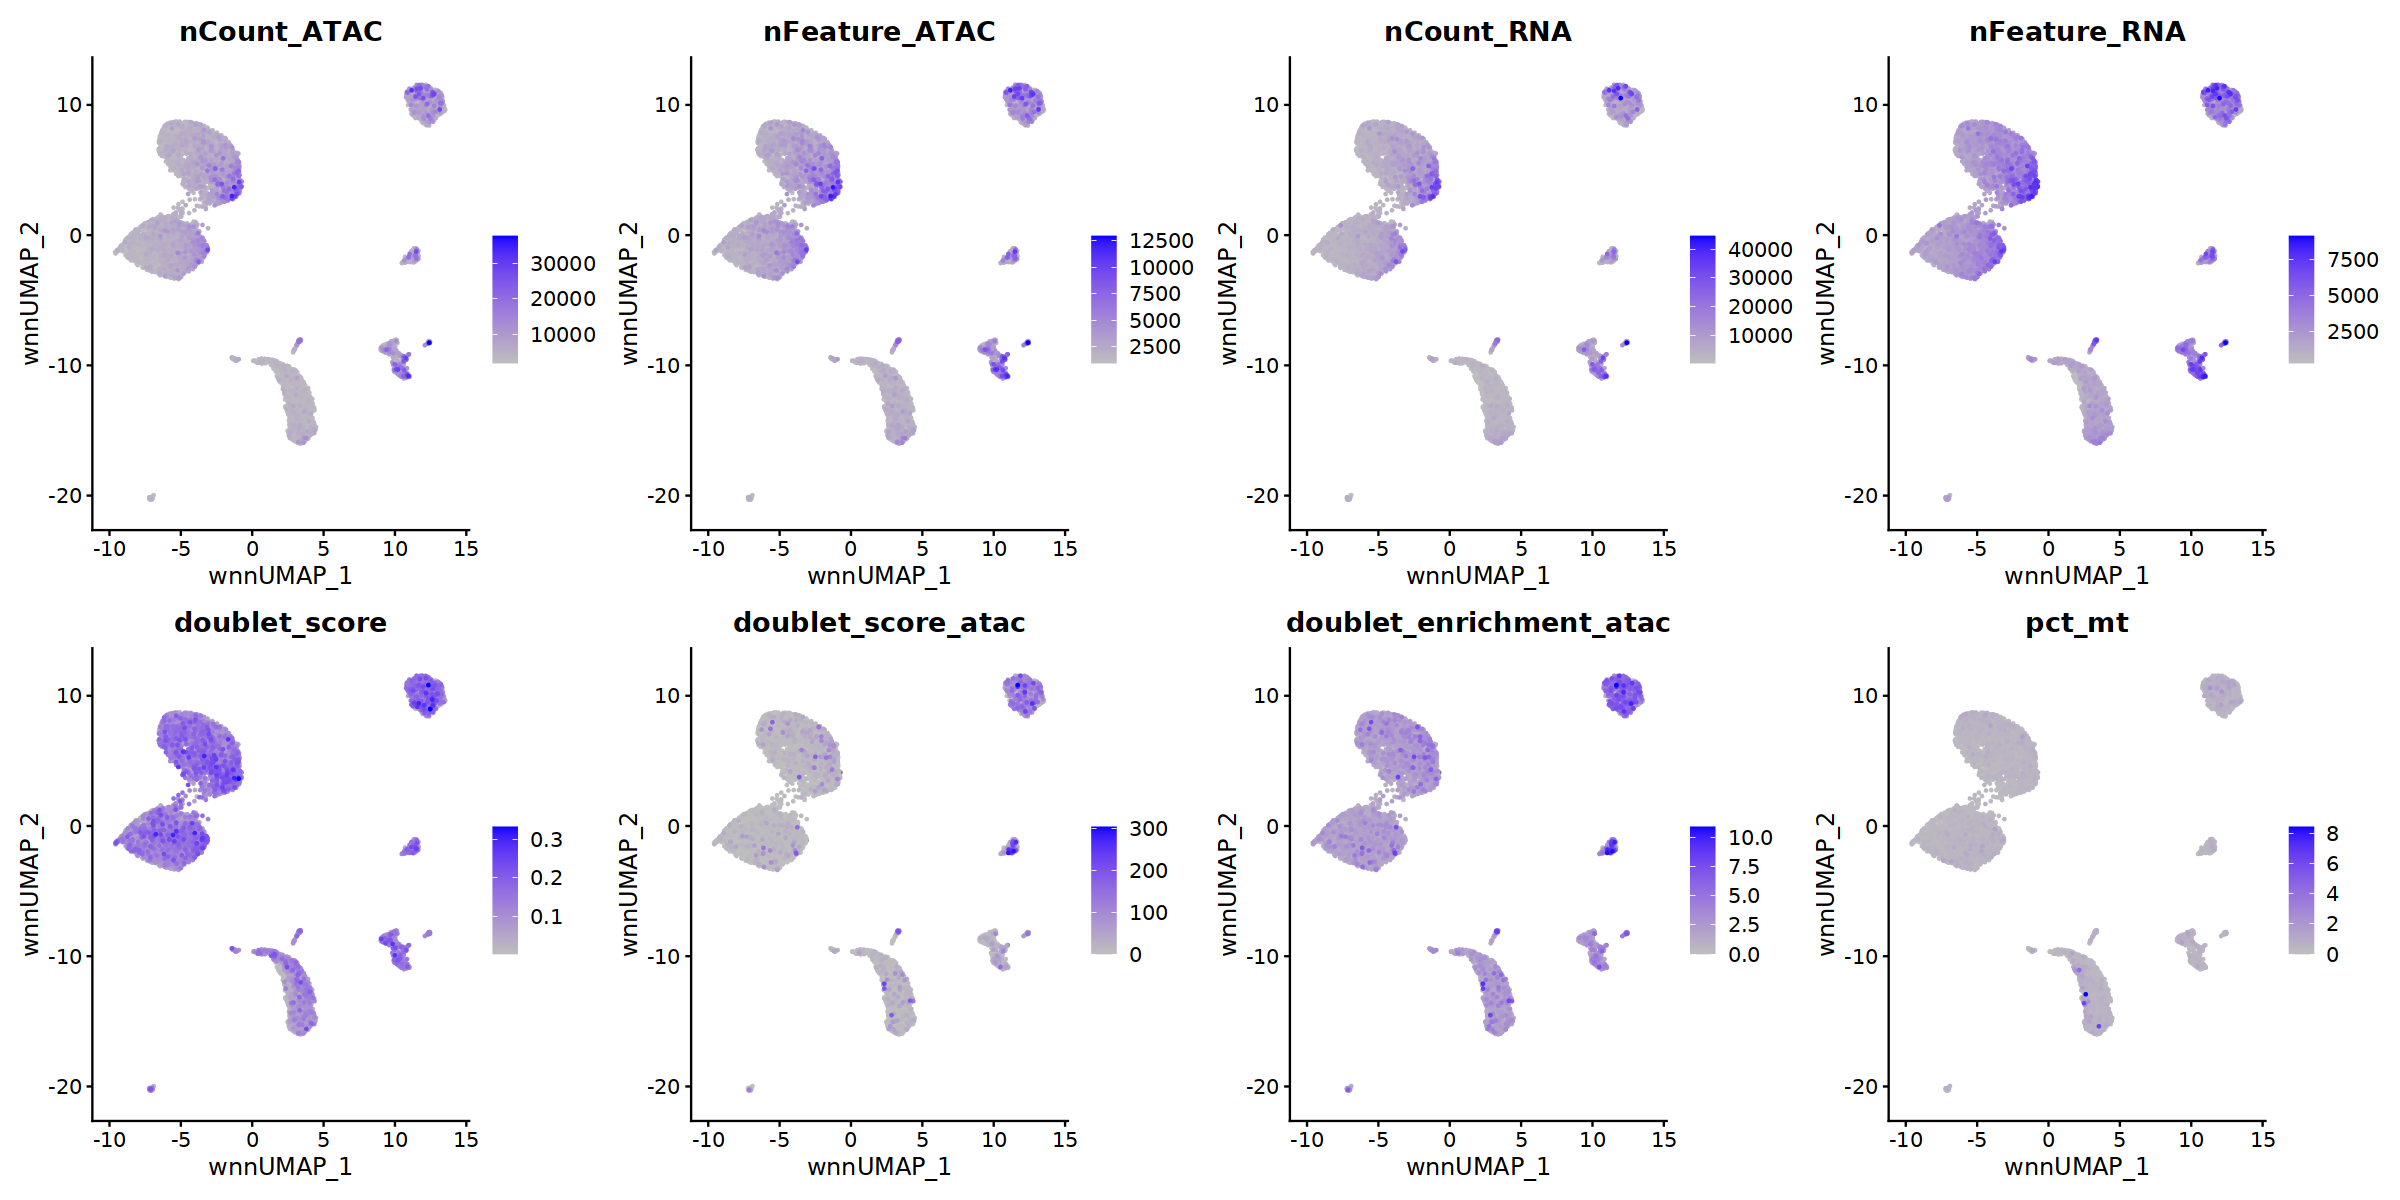

In [33]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

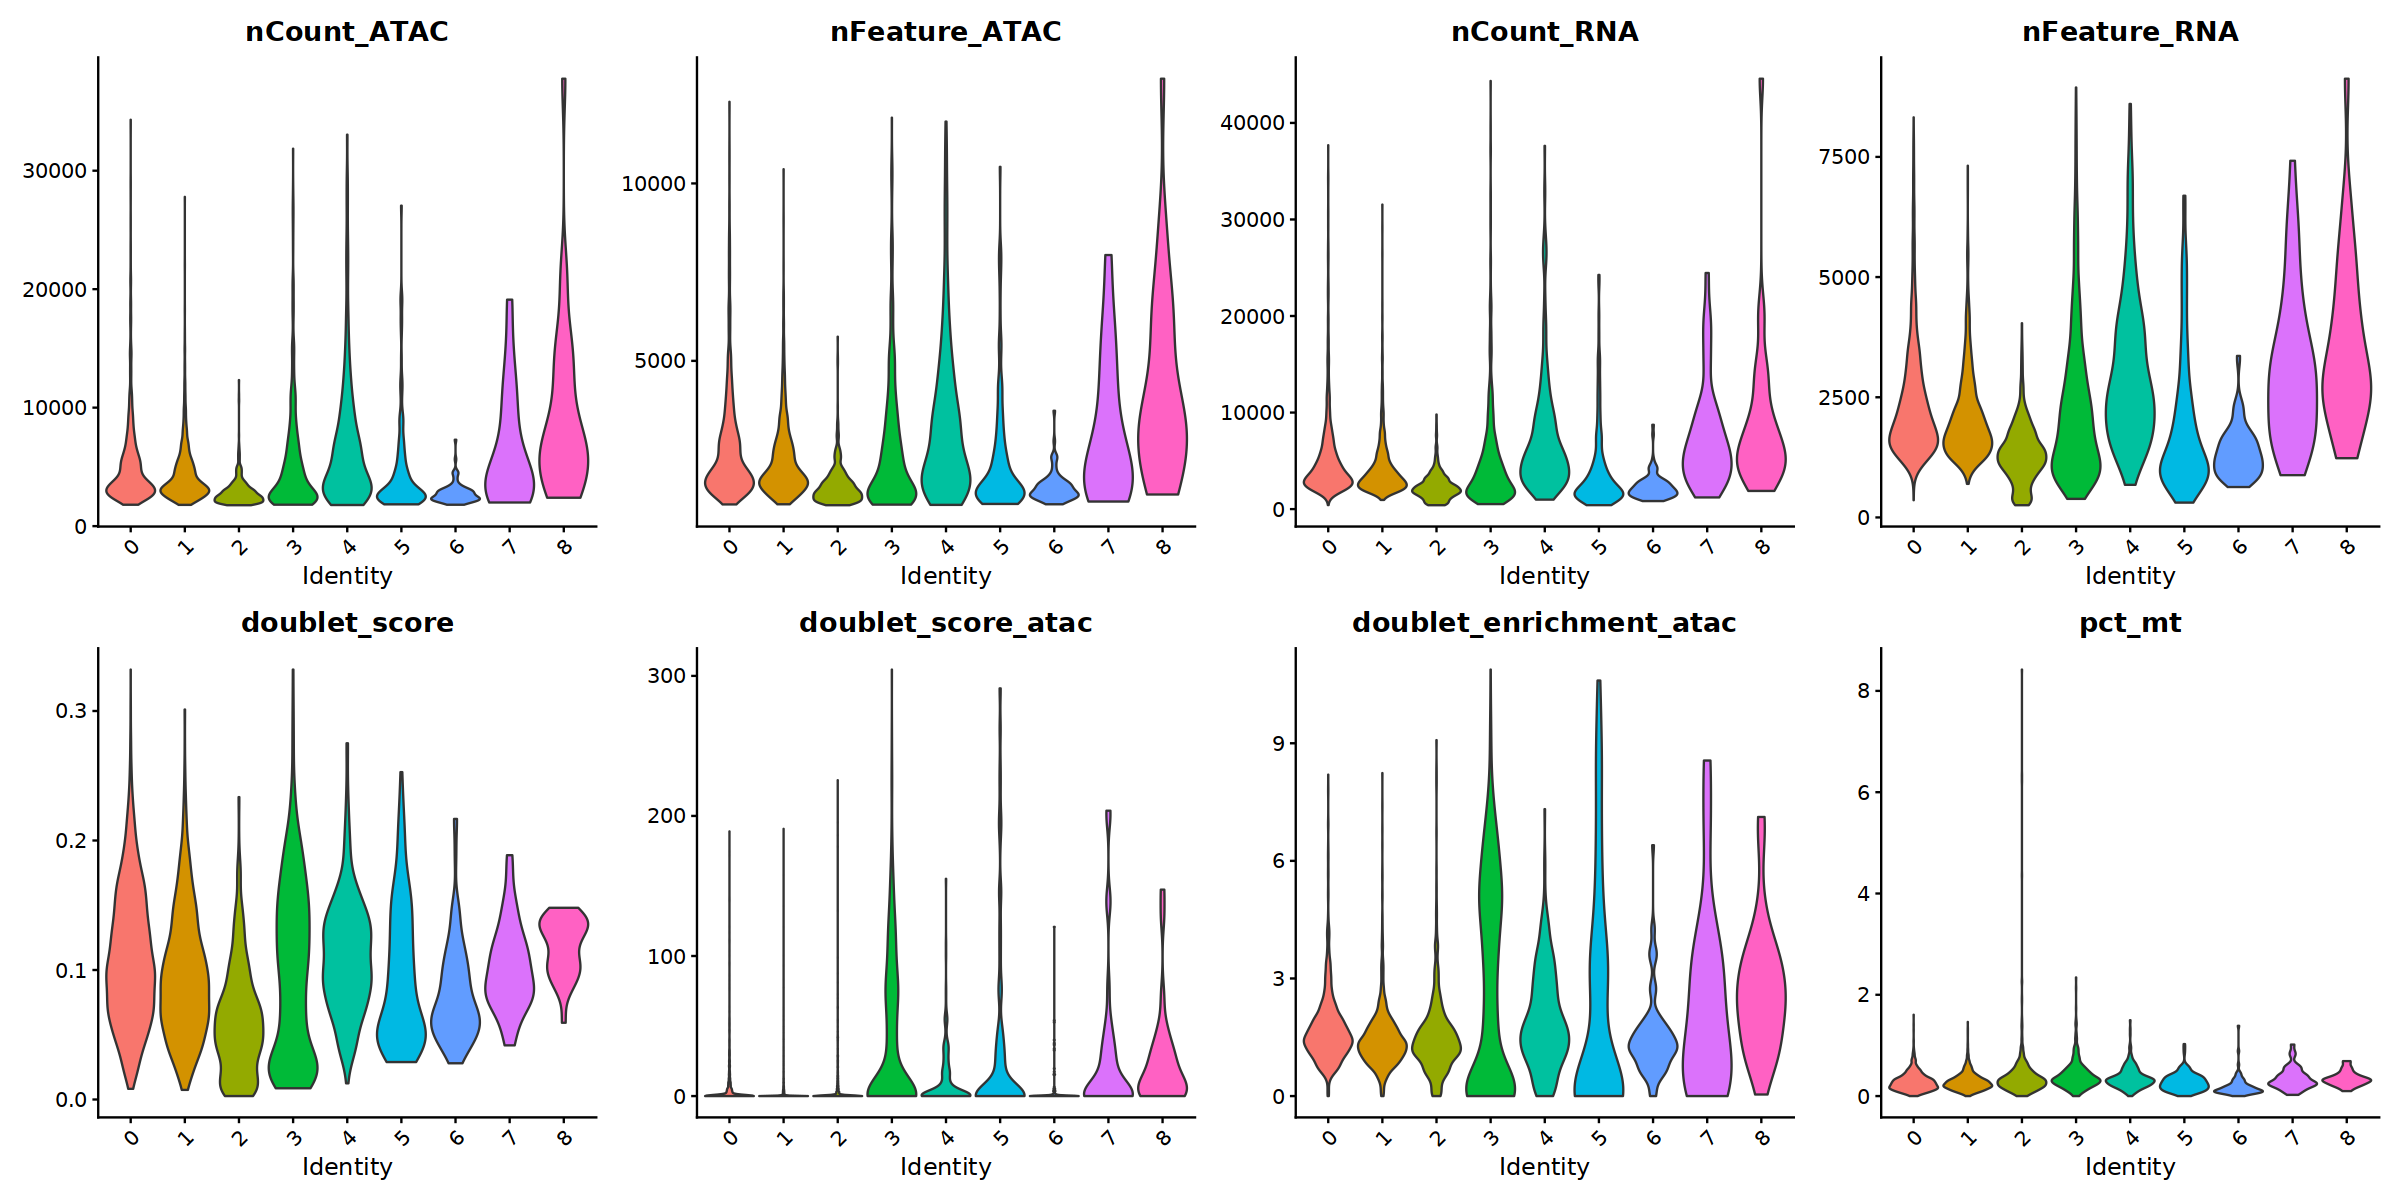

In [34]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

## Filter cells

low quality cells

In [35]:
seurat_obj <- subset(seurat_obj, idents = c("2", "6"), invert = TRUE)

In [36]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [37]:
keep_peaks <- data.frame(rowSums(as.matrix(seurat_obj[['ATAC']]@counts)) >= 1)
colnames(keep_peaks) <- "logical"
keep_peaks <- subset(keep_peaks, logical==TRUE)
seurat_obj[['ATAC']]@counts <- seurat_obj[['ATAC']]@counts[rownames(keep_peaks), ]
seurat_obj[['ATAC']]@data <- seurat_obj[['ATAC']]@data[rownames(keep_peaks), ]

### RNA

In [38]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [39]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

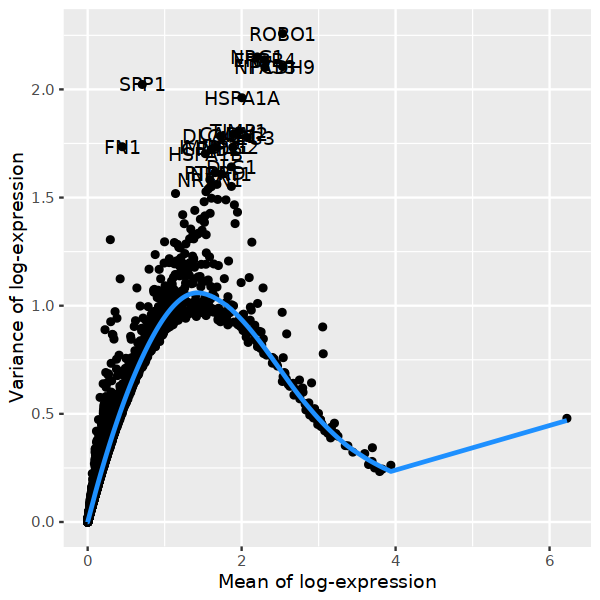

In [40]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [41]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 8957
[1] 8957


In [42]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  ROBO1, ERBB4, PCDH9, NPAS3, NRG1, CADM2, BICD1, GMDS, DLG2, SYNE2 
	   MIR99AHG, MEG3, SEMA3D, AFF3, DLGAP1, CDH4, BRINP3, NRXN1, SNTG1, PCDH7 
	   FGFR1, CTNNA3, PTPRD, SEMA3E, DLC1, INPP4B, GRID2, IMMP2L, NTN1, EPHA5 
Negative:  SPP1, PLXDC2, C1QC, C1QB, CD74, IFI30, C1QA, TGFBI, CD163, LRMDA 
	   RNASE1, SLC11A1, DOCK4, ZEB2, SLCO2B1, CD14, TYROBP, FMN1, LDLRAD4, STAB1 
	   ALOX5AP, LAPTM5, SFMBT2, LRP1, PTPRJ, DOCK8, FCER1G, TNS3, TBXAS1, VSIG4 
PC_ 2 
Positive:  C1QC, CADM1, IFI30, C1QB, C1QA, CD163, LRMDA, TYROBP, FCER1G, NRG1 
	   DOCK8, ADAP2, CD14, MERTK, ERBB4, LAPTM5, STAB1, CD74, APOC1, SLCO2B1 
	   TBXAS1, VSIG4, ALOX5AP, SLC11A1, MS4A6A, HMOX1, APBB1IP, CADM2, CAPG, PTPRJ 
Negative:  COL1A1, LAMA2, COL6A3, COL3A1, DCN, COL6A1, PTPRG, FN1, PDGFRB, ZEB1 
	   RORA, TIMP3, CDH11, PRICKLE1, COL4A2, NTM, MGP, COL4A1, COL5A2, IGFBP5 
	   SVIL, BICC1, SPARC, CACNA1C, IGFBP2, LAMC3, TIMP1, BGN, TSPAN5, ADAM12 
PC_ 3 
Positive:  

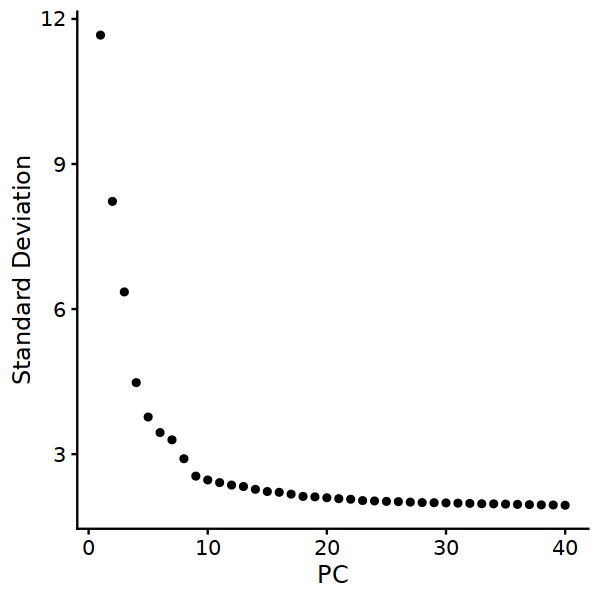

In [43]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [44]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [45]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



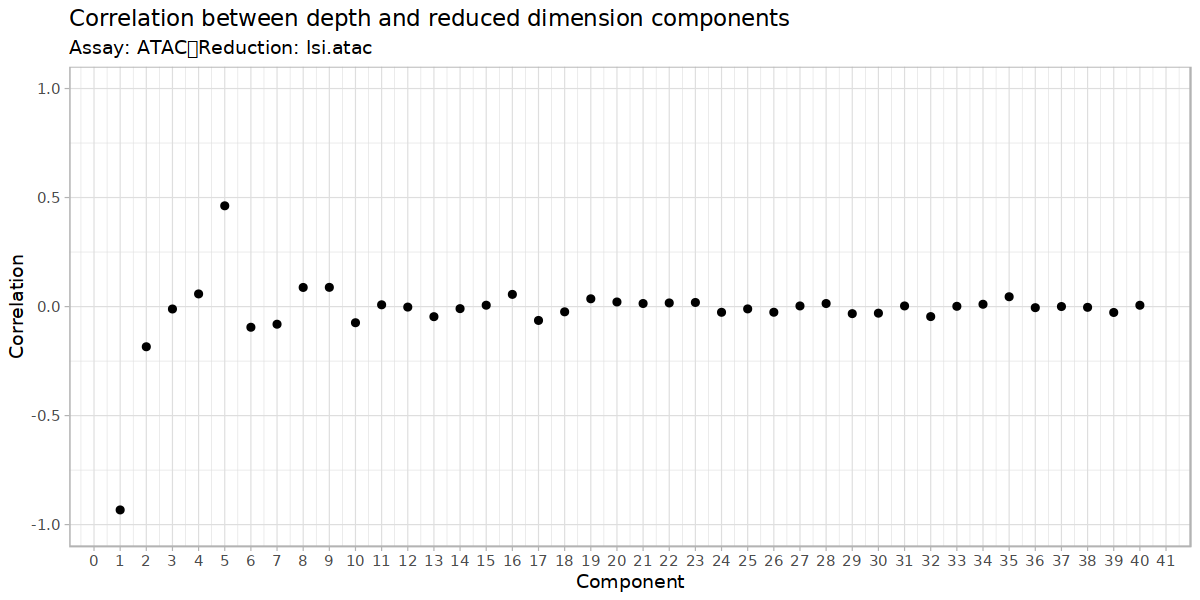

In [46]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

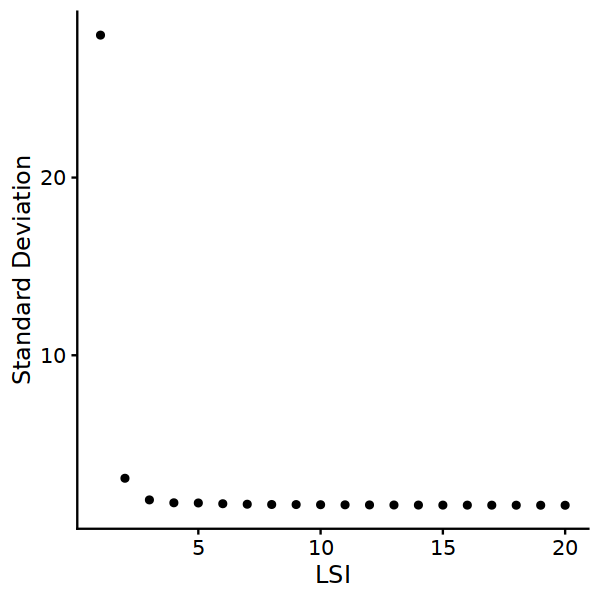

In [47]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [48]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [49]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

09:30:48 UMAP embedding parameters a = 0.9922 b = 1.112

09:30:48 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

09:30:50 Initializing from normalized Laplacian + noise (using irlba)

09:30:50 Commencing optimization for 500 epochs, with 144266 positive edges

09:31:05 Optimization finished



In [50]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4743
Number of edges: 176564

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9695
Number of communities: 5
Elapsed time: 0 seconds


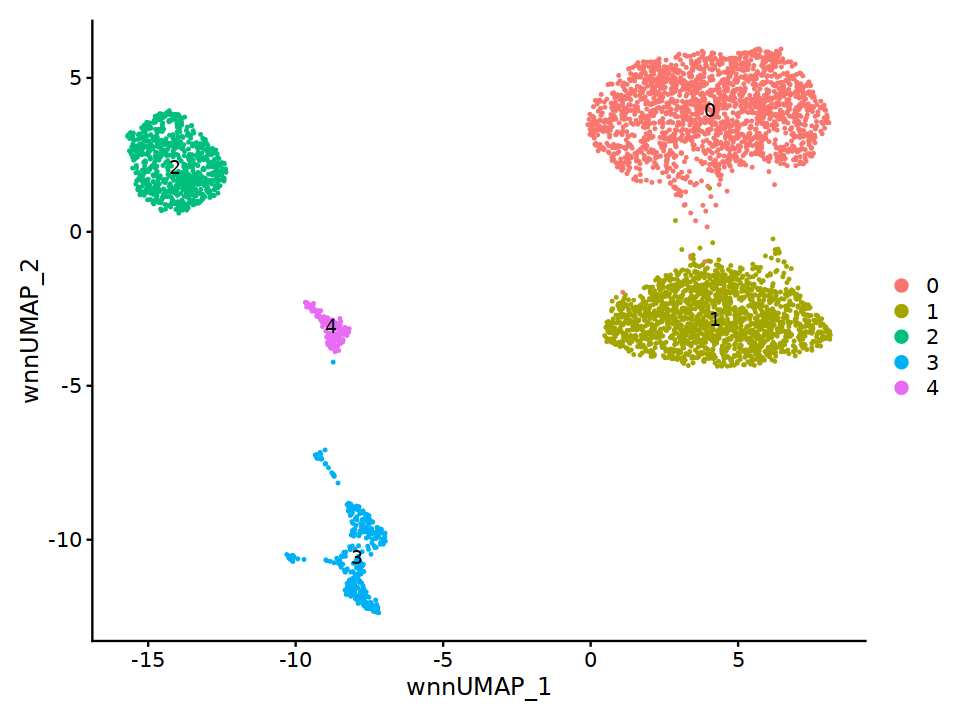

In [51]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

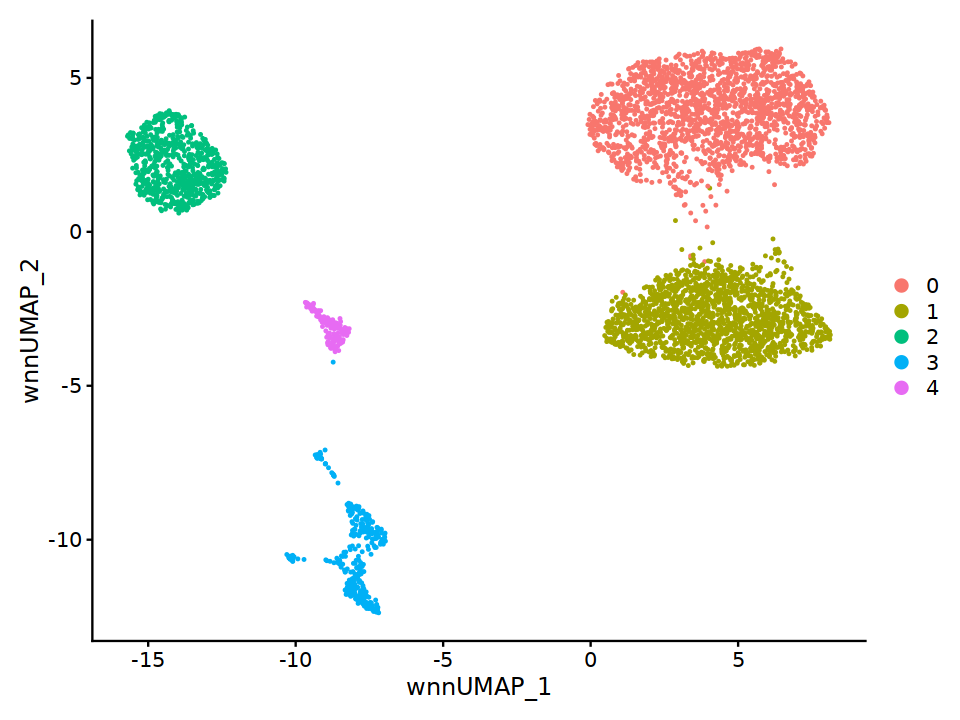

In [52]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap") 

In [53]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  3,
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.3,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 358
Number of edges: 10294

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8834
Number of communities: 4
Elapsed time: 0 seconds


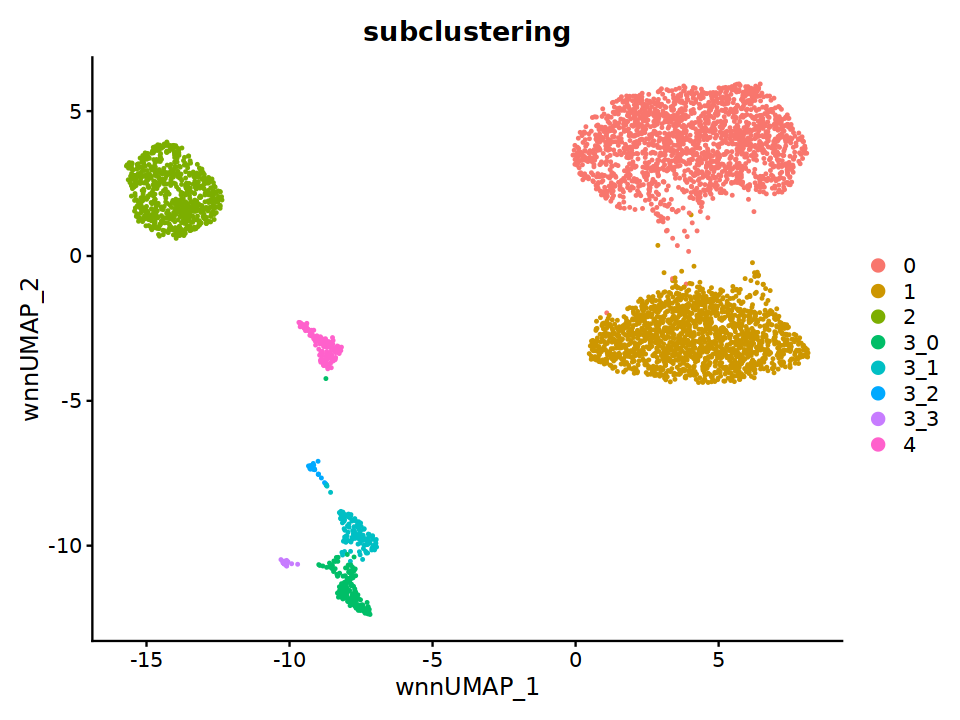

In [54]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering", label = F, label.size = 6)

In [55]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data[["subclustering"]])

In [56]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 2

Calculating cluster 0

Calculating cluster 1

Calculating cluster 3_0

Calculating cluster 3_1

Calculating cluster 4

Calculating cluster 3_3

Calculating cluster 3_2



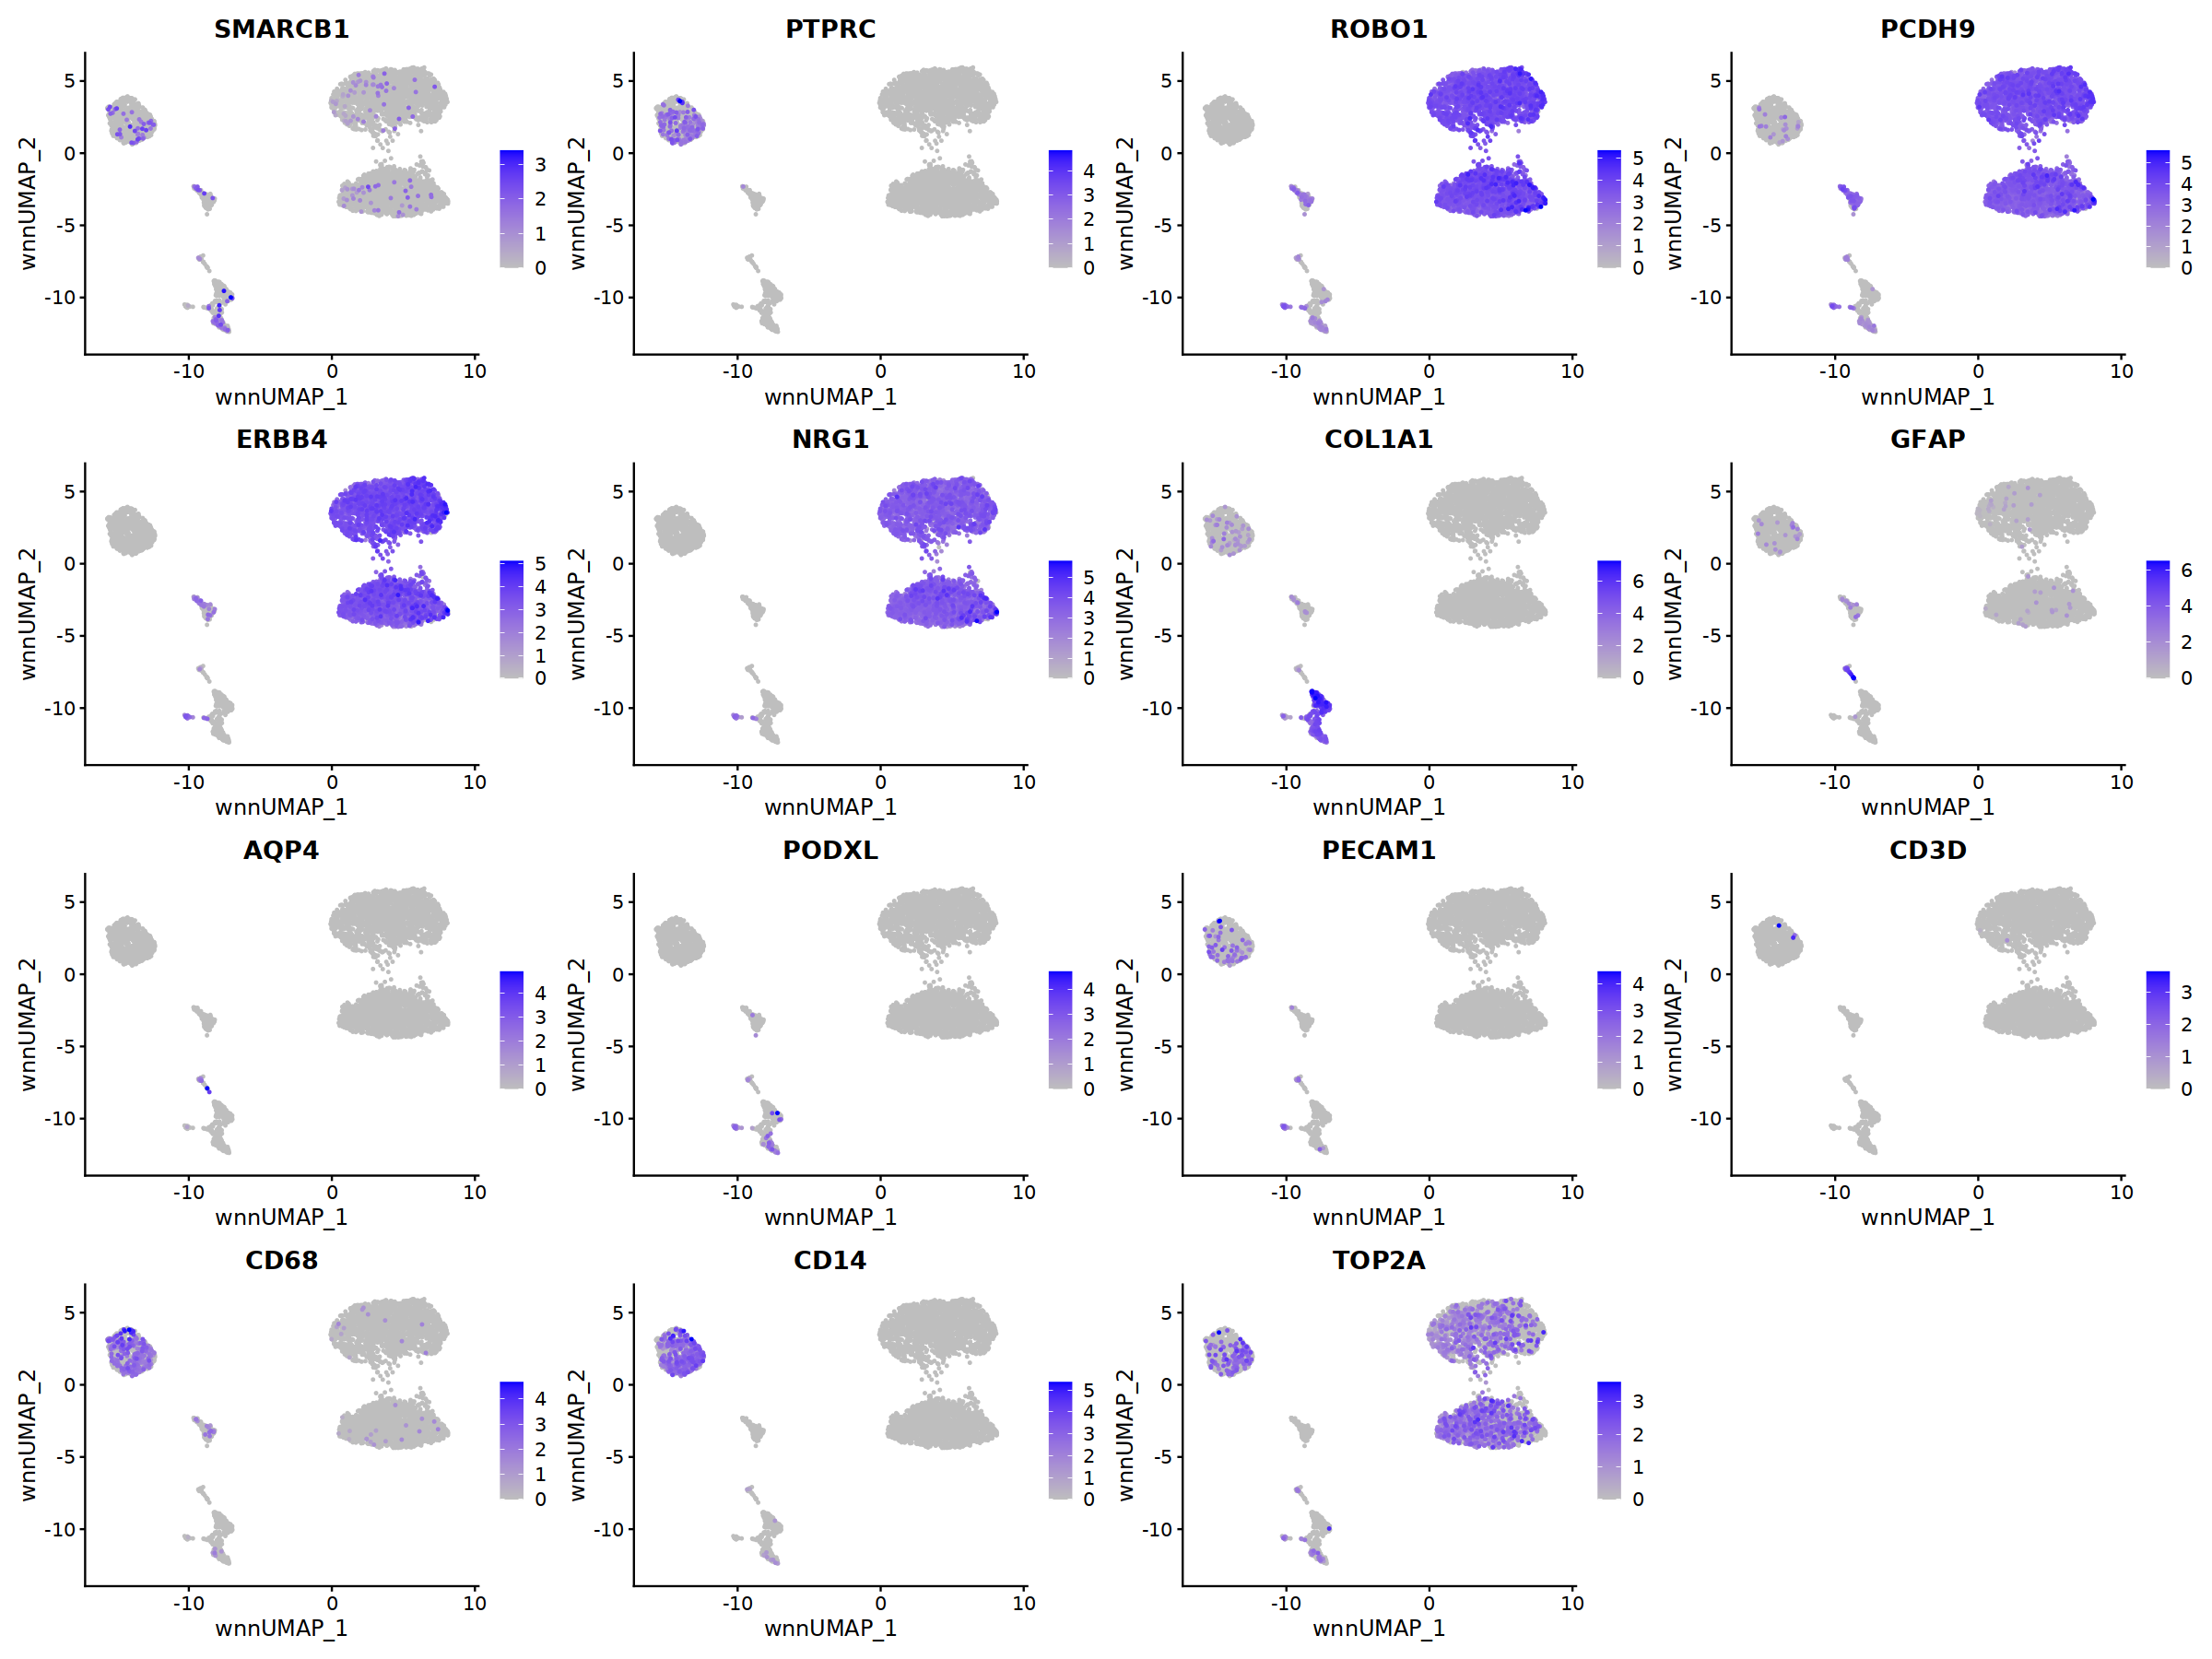

In [57]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC","ROBO1","PCDH9", "ERBB4","NRG1",
                              "COL1A1","GFAP", "AQP4","PODXL", 
                              "PECAM1","CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),order=T)

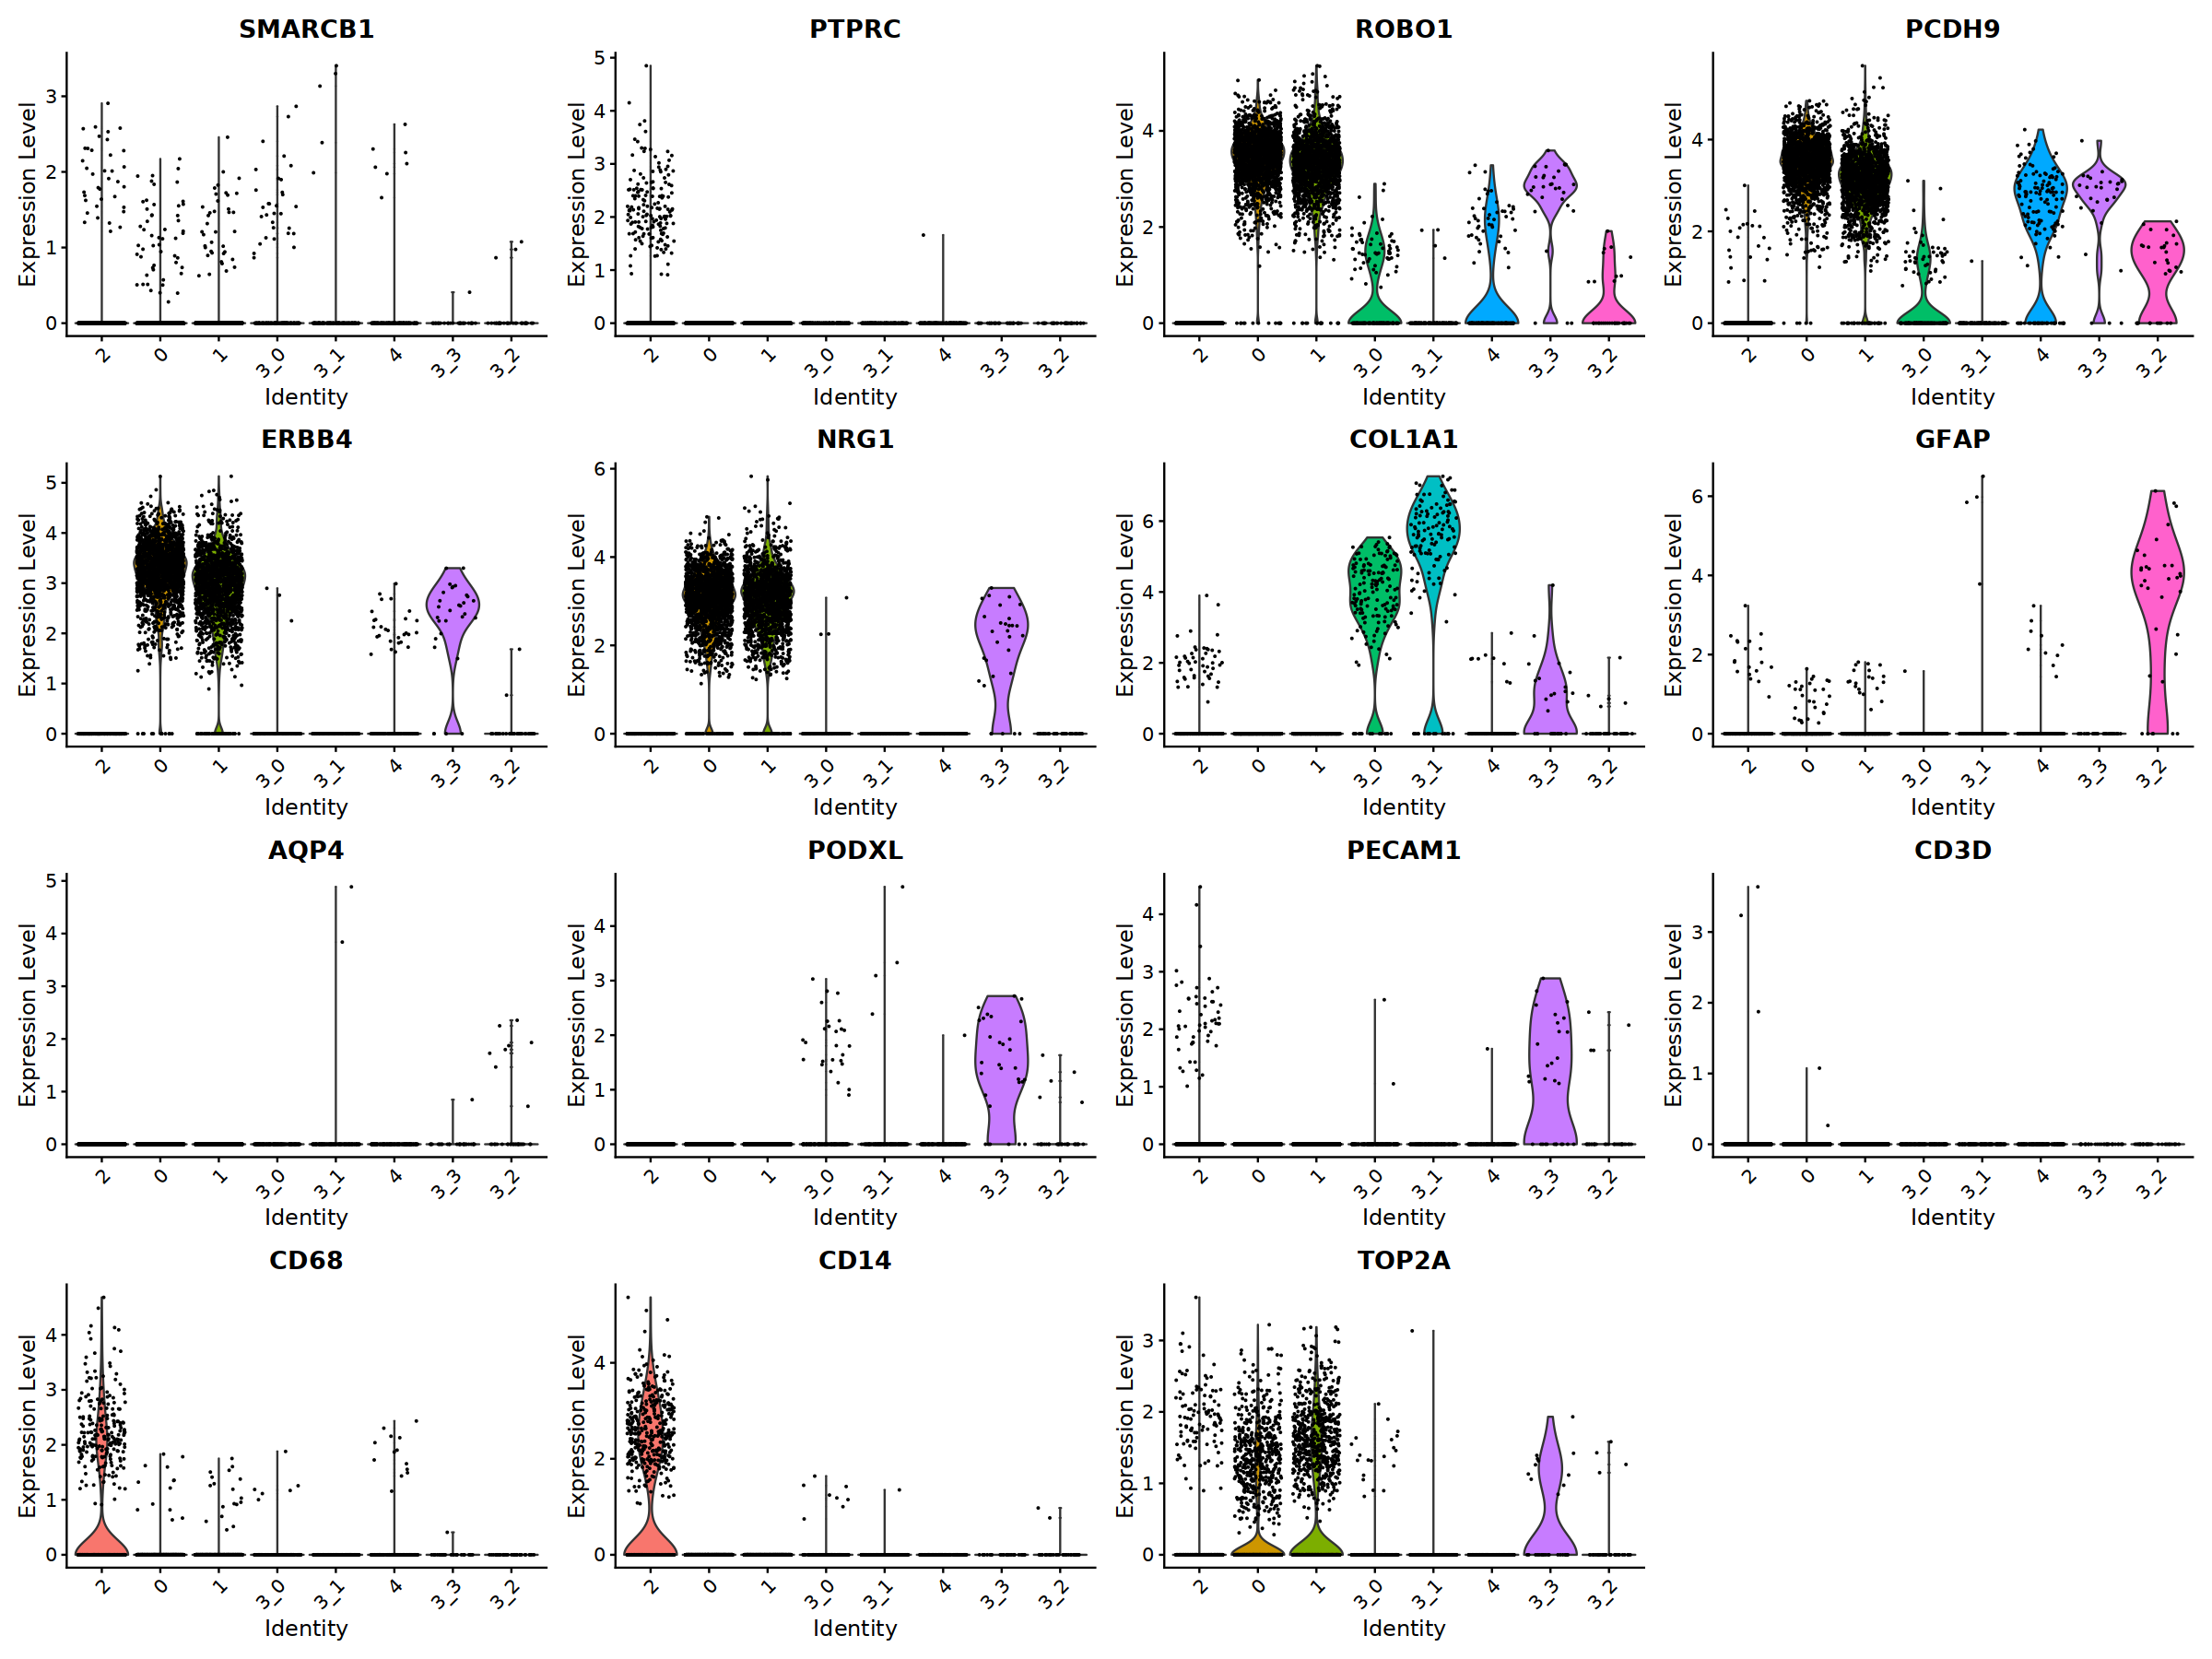

In [58]:
VlnPlot(seurat_obj, feature=vars2plot)

In [59]:
rna.markers %>% 
  dplyr::filter(cluster == "4") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
FRMD5,0.000000e+00,4.688097,0.783,0.024,0.000000e+00,4,FRMD5
PPP2R2B,0.000000e+00,4.130674,0.658,0.003,0.000000e+00,4,PPP2R2B
RNF2201,4.021111e-142,3.719121,0.678,0.087,1.114732e-137,4,RNF220
TMTC2,5.787453e-238,3.689305,0.586,0.029,1.604398e-233,4,TMTC2
SGK11,1.349169e-221,3.666451,0.625,0.037,3.740165e-217,4,SGK1
LSAMP,0.000000e+00,3.662318,0.605,0.007,0.000000e+00,4,LSAMP
PRUNE2,0.000000e+00,3.600851,0.618,0.003,0.000000e+00,4,PRUNE2
NRXN3,1.796107e-303,3.501864,0.434,0.006,4.979167e-299,4,NRXN3
CRYAB1,2.414846e-167,3.420714,0.855,0.129,6.694435e-163,4,CRYAB


### Rename

In [60]:
rename_clusters <- c("0"="Tumor SOX2-OT", 
                     "1"="Tumor GRID2",
                     "2"="Monocytes-Macrophages", 
                     "3_0"="Fibroblast 1",
                     "3_1"="Fibroblast 2",  
                     "3_2"="Astrocytes", 
                     "3_3"="Podocytes-Endothelial cells",
                     "4"="Oligodendrocytes")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [61]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep]

In [62]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [63]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [64]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [65]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Immune

Calculating cluster Tumor

Calculating cluster Other stromal



In [66]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

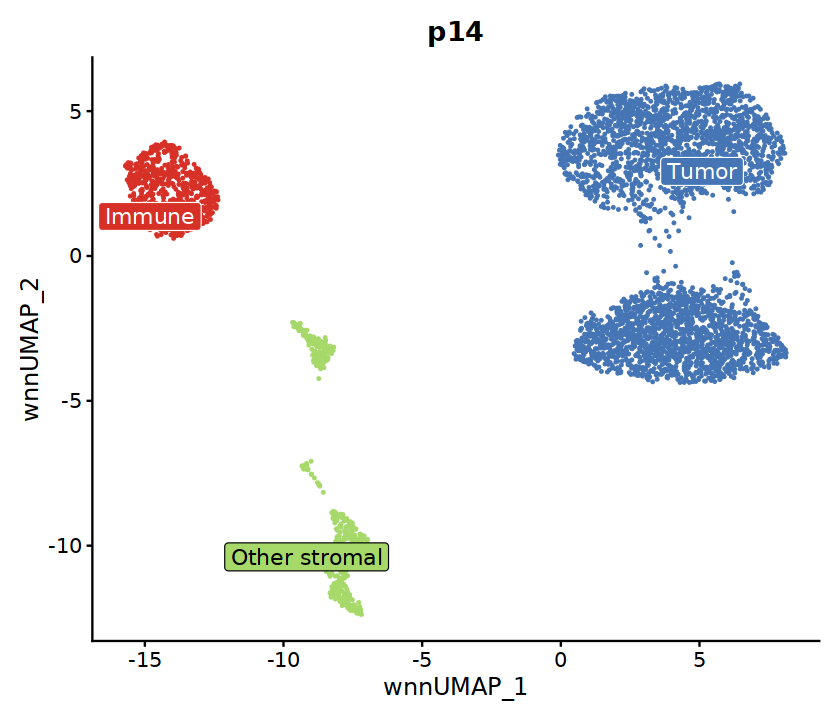

In [67]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [68]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [69]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [70]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

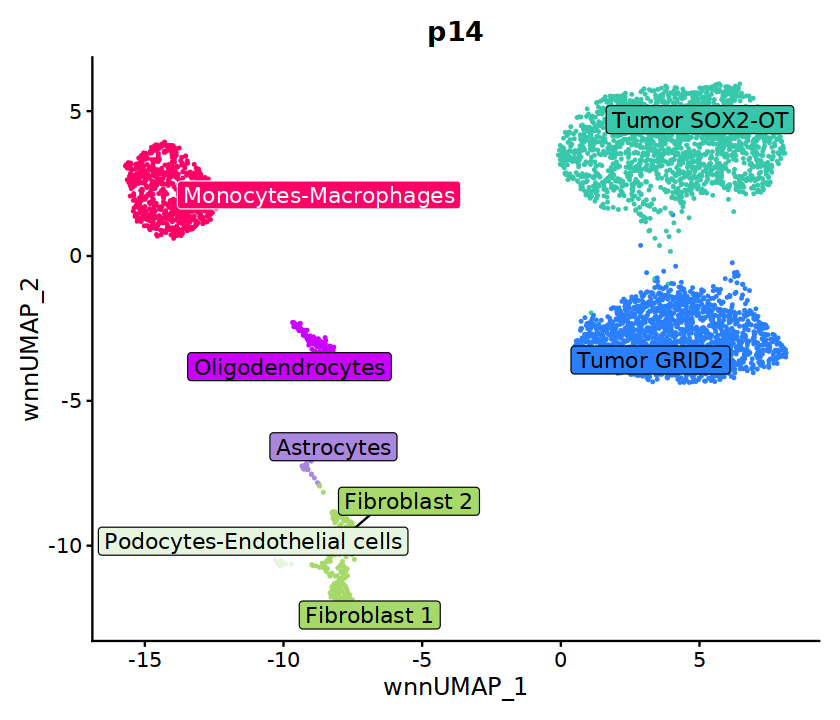

In [71]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [72]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

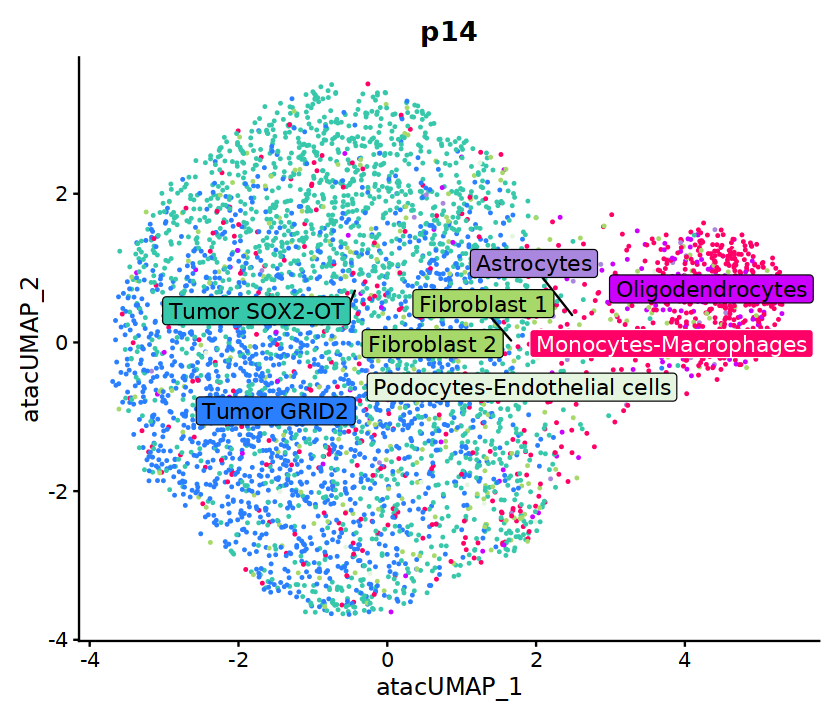

In [73]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [74]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

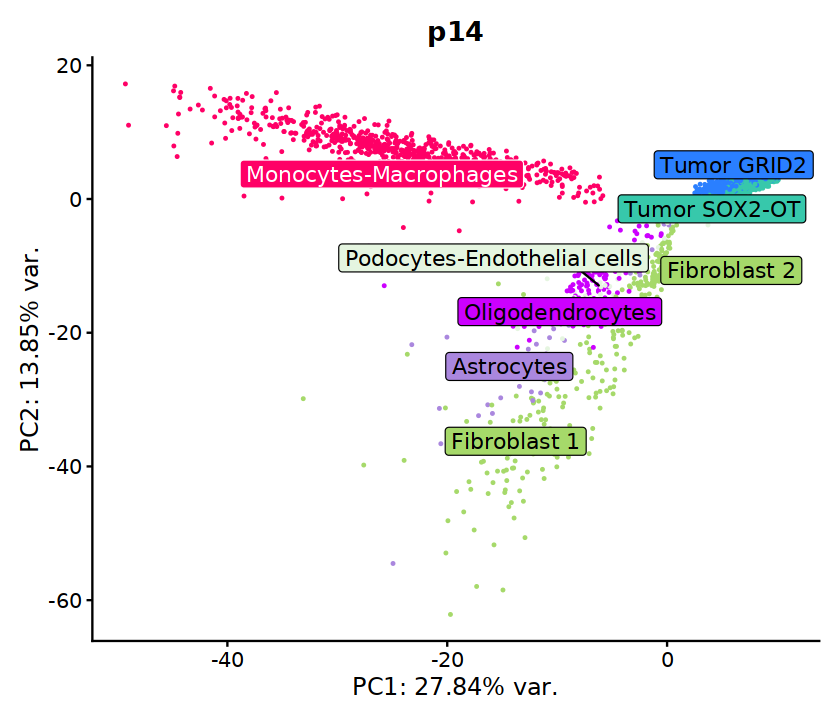

In [75]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

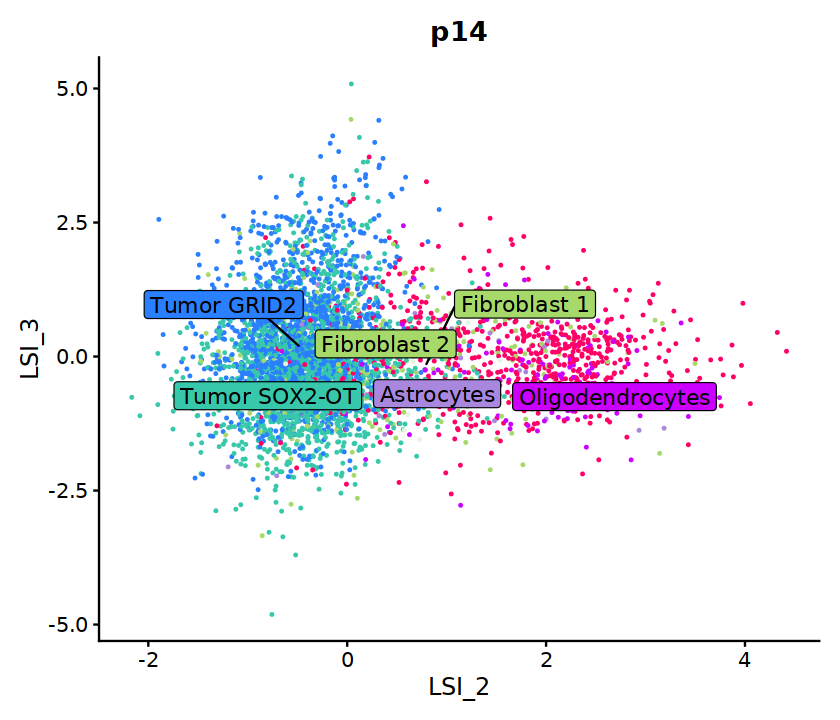

In [76]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

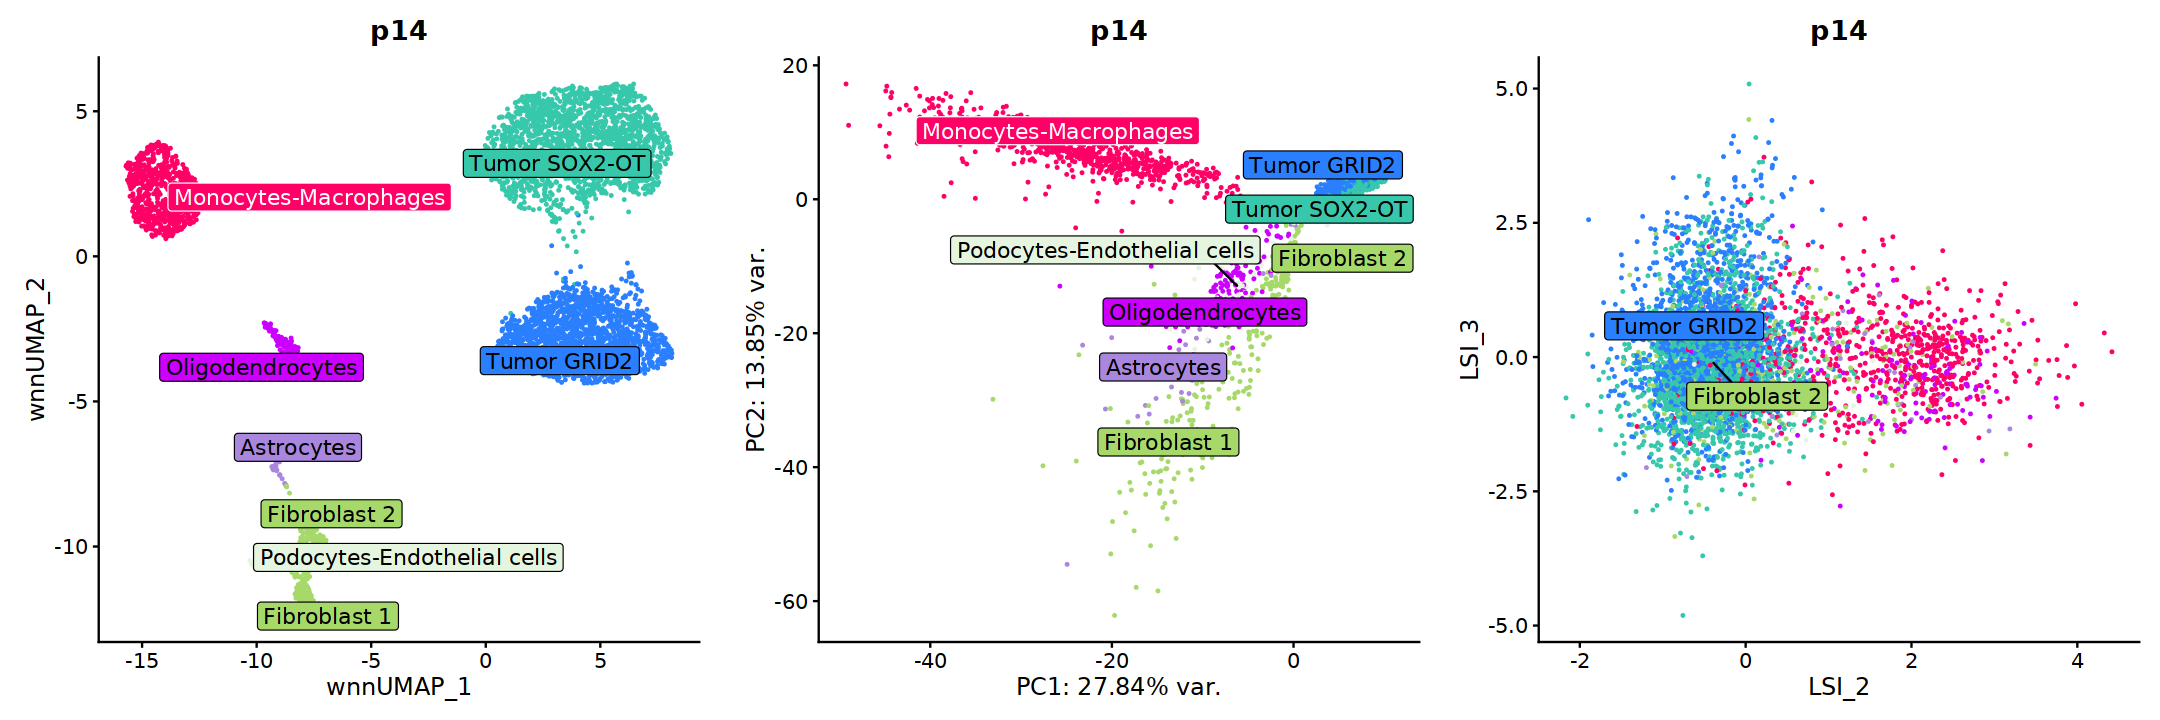

In [77]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [78]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

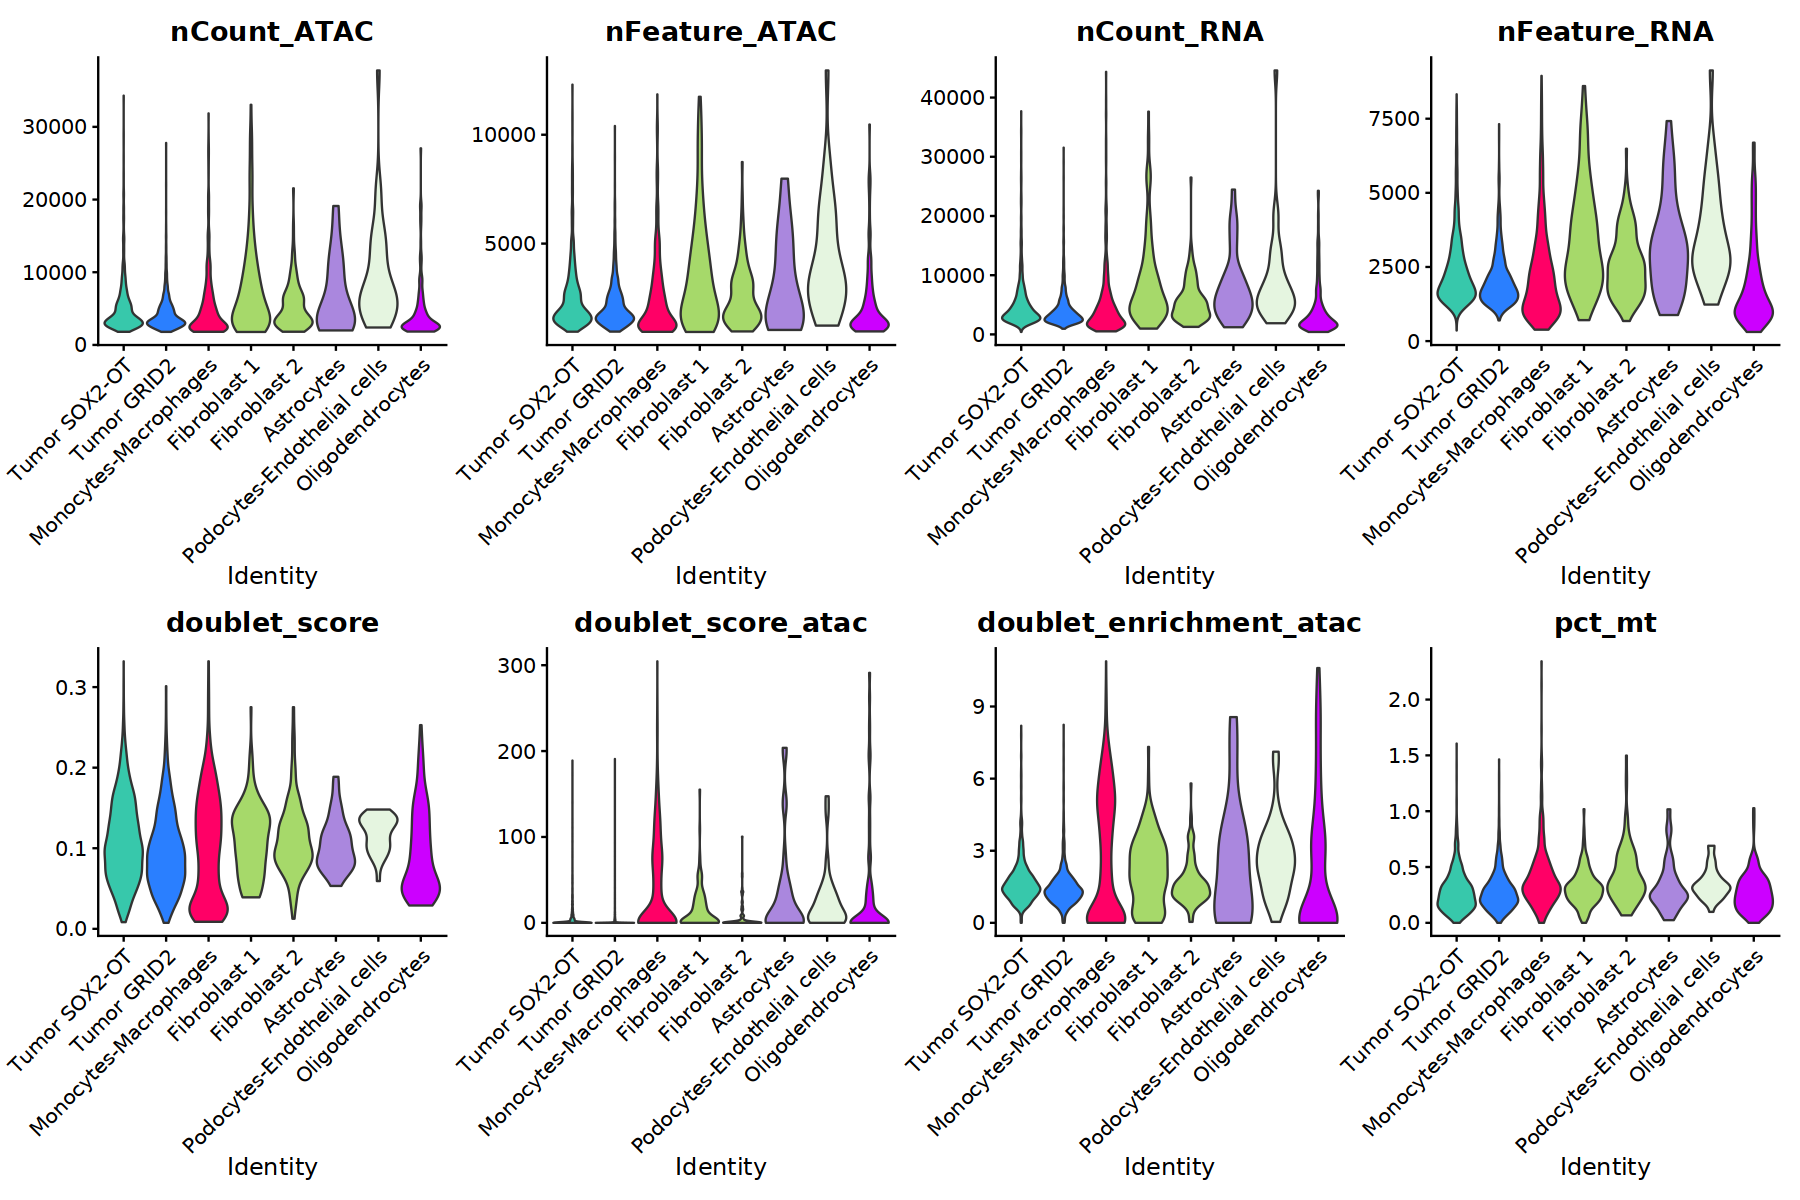

In [79]:
options(repr.plot.width = 15, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars,cols=colors_list, ncol = 4, pt.size = 0)

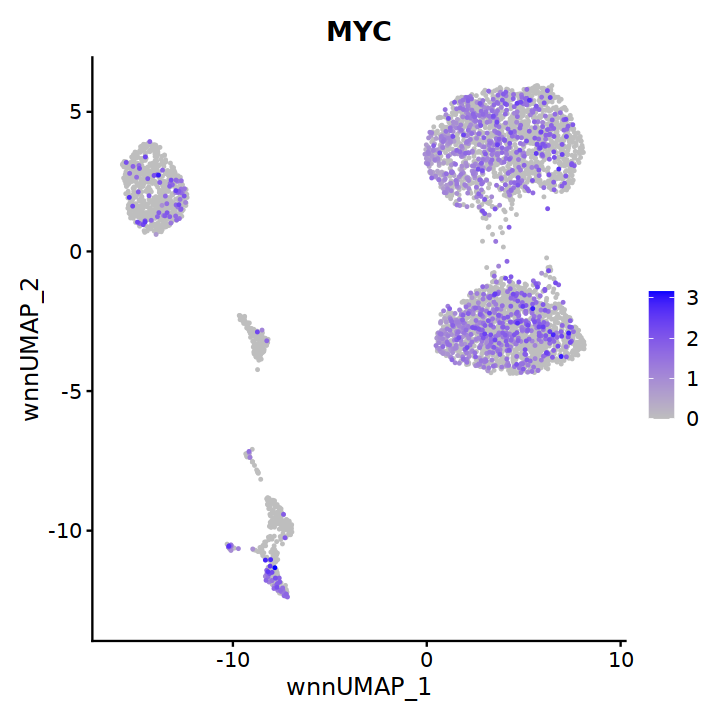

In [80]:
options(repr.plot.width = 6, repr.plot.height = 6)
FeaturePlot(seurat_obj, reduction = "wnn.umap", feature="MYC", 
            cols = c("gray", "blue"),order=T)

Oligocendrocytes

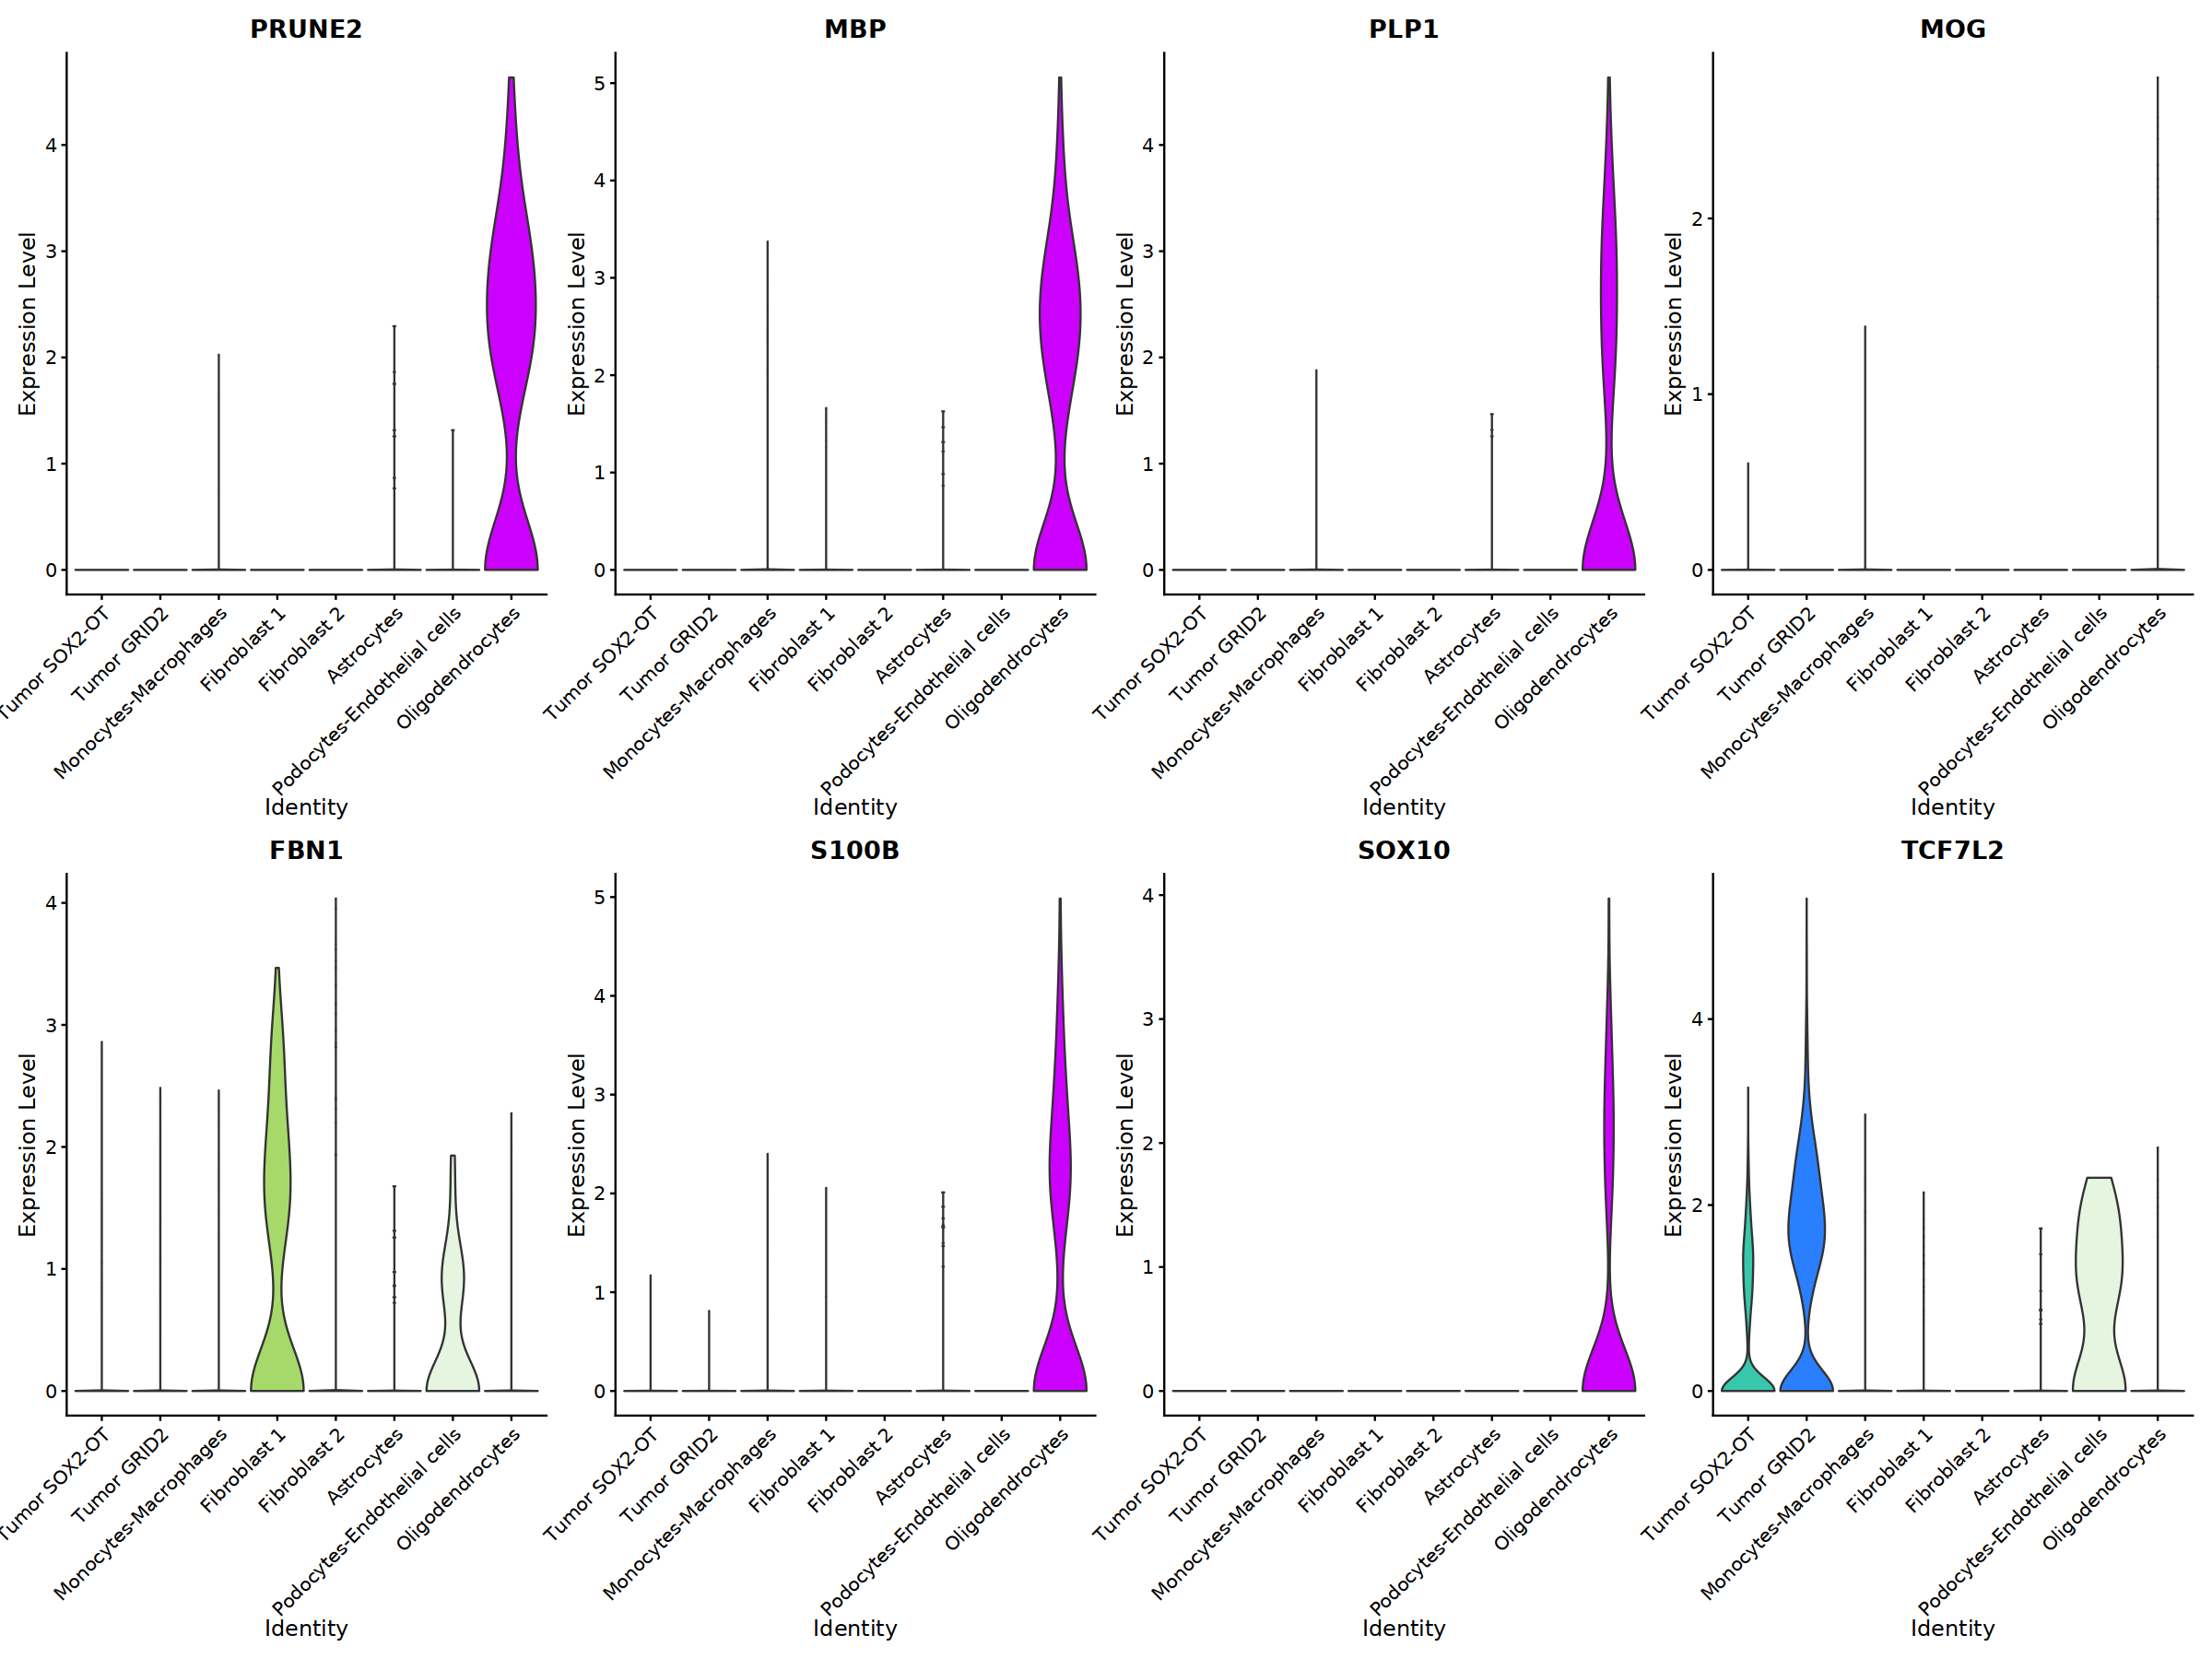

In [81]:
options(repr.plot.width = 20, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=c("PRUNE2", "MBP","PLP1", "MOG", "FBN1", "S100B",
                             "SOX10", "TCF7L2"),
       cols=colors_list, ncol = 4, pt.size = 0)

Endothelial markers

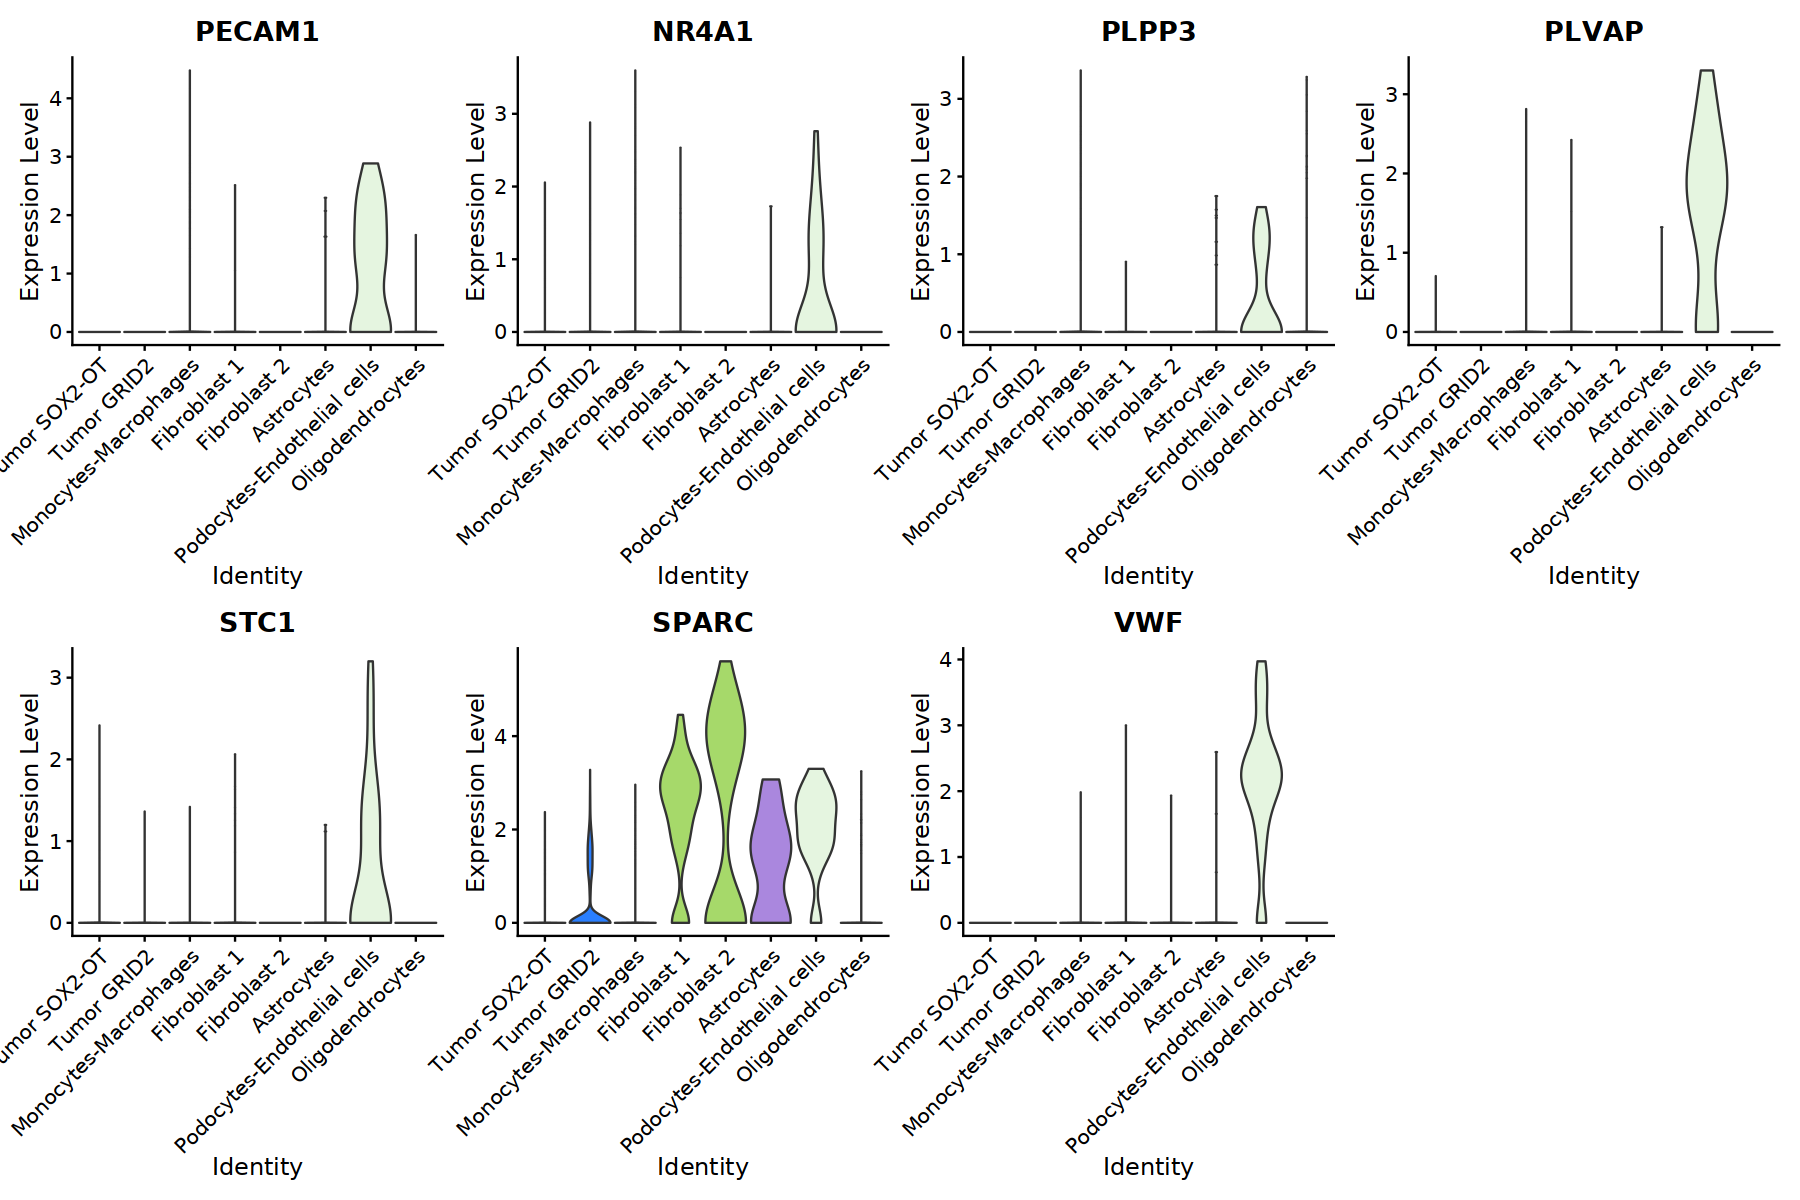

In [82]:
options(repr.plot.width = 15, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=c("PECAM1","NR4A1", "PLPP3","PLVAP",
                              "STC1", "SPARC", "VWF"),
        cols=colors_list, ncol = 4, pt.size = 0)

Pseudo-bulk per cluster

In [83]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("ROBO1", "PCDH9", "ERBB4", "NRG1"), markers) ## common markers to all clusters

In [84]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

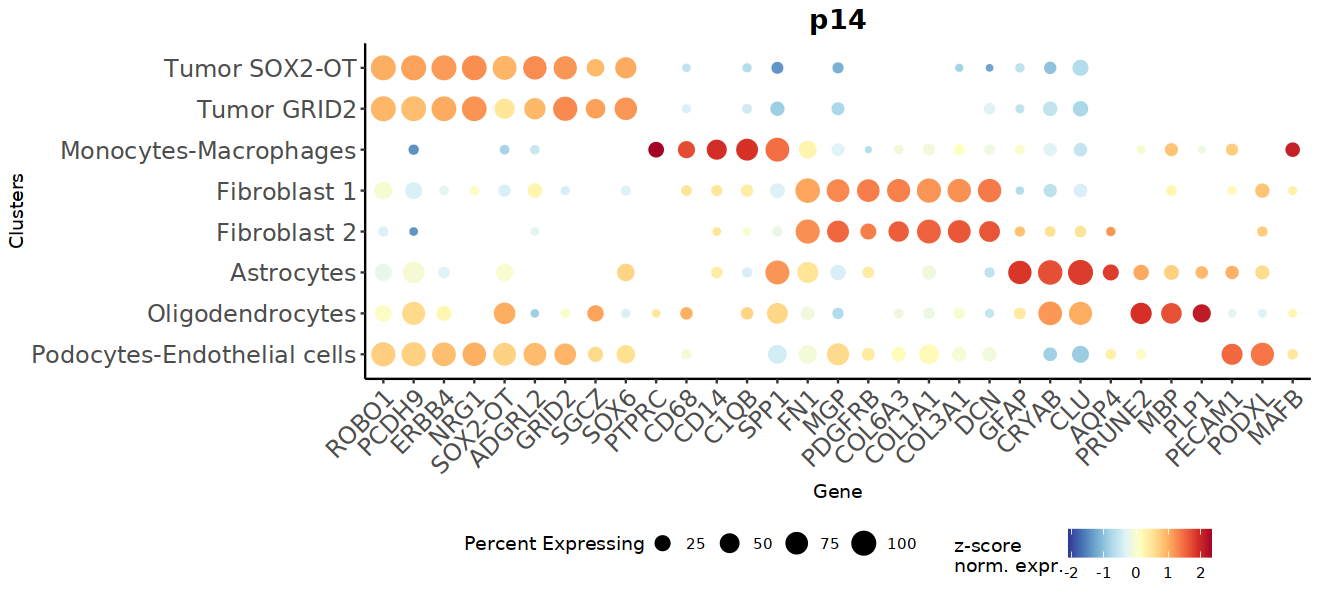

In [85]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, unique(markers), TRUE,patient)
dp1

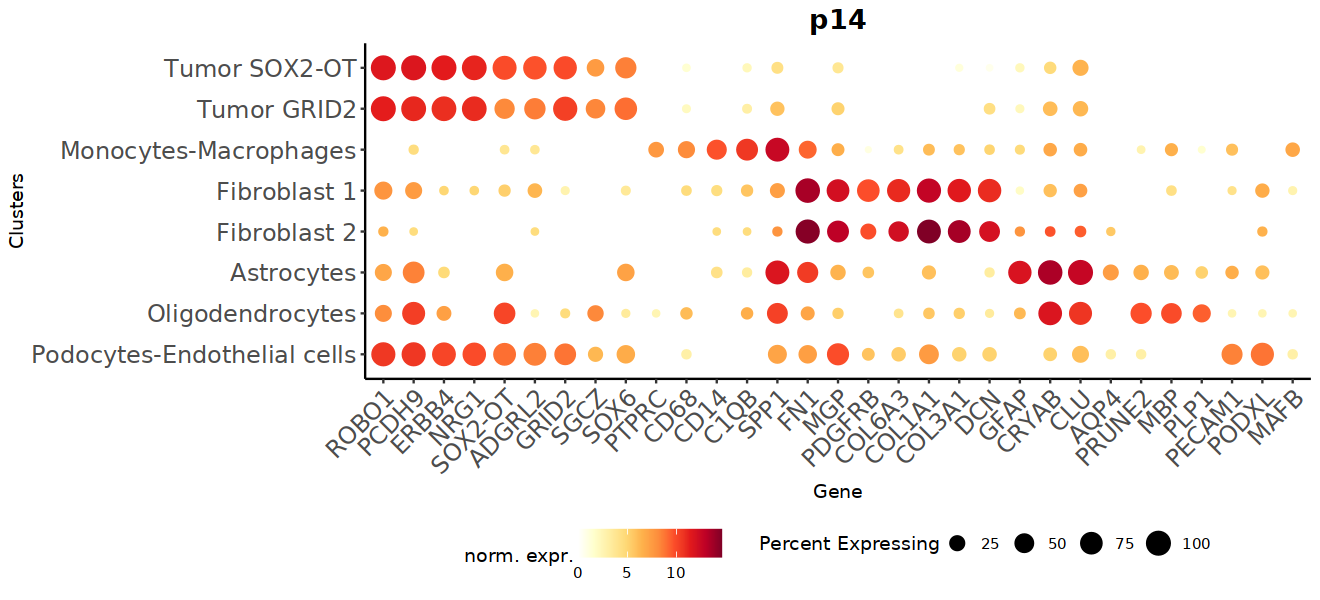

In [86]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, unique(markers), FALSE,patient)
dp2

In [87]:
ggsave(plot = dp1, width = 11, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save 

In [88]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [89]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [90]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [91]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    